<a href="https://colab.research.google.com/github/alyPoint/CEFET---Processamento-de-Sinais-I-140826/blob/main/Pratica_7/DSP_1_PRATICA_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Questão 1 - Letra a)


--- Função de Transferência H(z) para r = 0.5 ---
        2                    
0.0747⋅z  + 0.1495⋅z + 0.0747
─────────────────────────────
     2                       
    z  - 0.9511⋅z + 0.25     

--- Função de Transferência H(z) para r = 0.8 ---
        2                    
0.0296⋅z  + 0.0592⋅z + 0.0296
─────────────────────────────
     2                       
    z  - 1.5217⋅z + 0.64     

--- Função de Transferência H(z) para r = 0.95 ---
        2                    
0.0239⋅z  + 0.0477⋅z + 0.0239
─────────────────────────────
     2                       
    z  - 1.807⋅z + 0.9025    


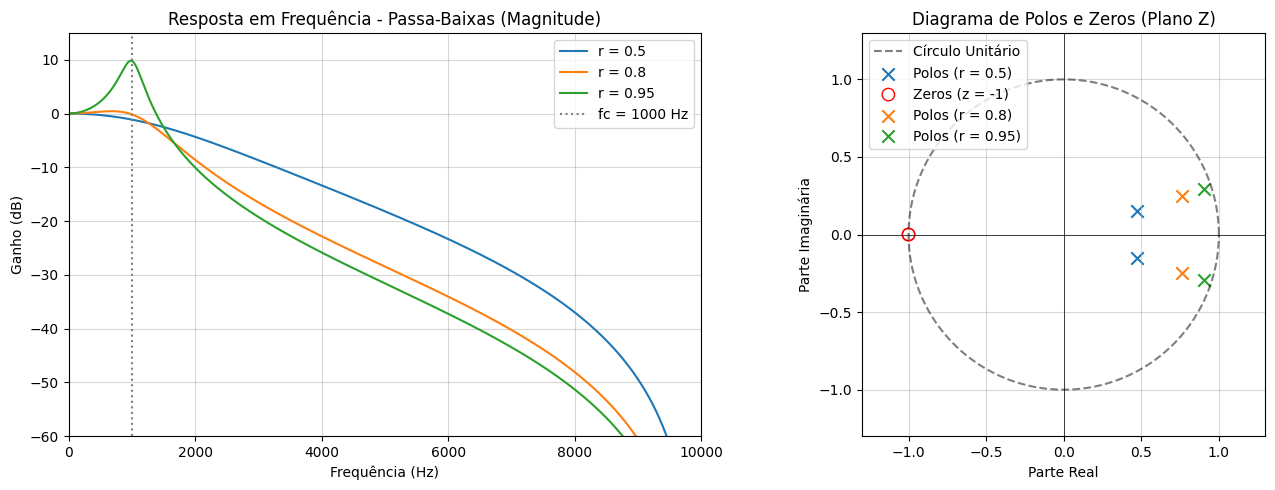

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Passa-Baixas
fs = 20000  # Frequência de amostragem (Hz)
fc = 1000  # Frequência de corte / ressonância (Hz)
wc = 2 * np.pi * fc / fs  # Frequência digital normalizada (rad/amostra)

# Variável simbólica z para impressão da equação
z = sp.Symbol('z')

# Valores de r para investigação
valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário para o diagrama de polos e zeros
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Coeficientes do denominador de 2ª ordem
  m1 = -2 * r * np.cos(wc)
  m2 = r**2

  # Ganho de normalização K para ganho unitário (0 dB) em DC (z = 1)
  K = (1 + m1 + m2) / 4

  # Numerador (dois zeros em z = -1) e Denominador
  num = K * np.array([1, 2, 1])
  den = np.array([1, m1, m2])

  # Montagem e impressão da equação H(z) com potências positivas de z
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (z = -1)',
    )

# Formatação do gráfico de Magnitude
ax1.set_title('Resposta em Frequência - Passa-Baixas (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 1000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 15)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Questão 1 - Letra b)


--- Função de Transferência H(z) para r = 0.5 ---
        2                    
0.5148⋅z  - 1.0295⋅z + 0.5148
─────────────────────────────
      2                      
     z  - 0.809⋅z + 0.25     

--- Função de Transferência H(z) para r = 0.8 ---
        2                    
0.7336⋅z  - 1.4672⋅z + 0.7336
─────────────────────────────
     2                       
    z  - 1.2944⋅z + 0.64     

--- Função de Transferência H(z) para r = 0.95 ---
        2                    
0.8599⋅z  - 1.7198⋅z + 0.8599
─────────────────────────────
    2                        
   z  - 1.5371⋅z + 0.9025    


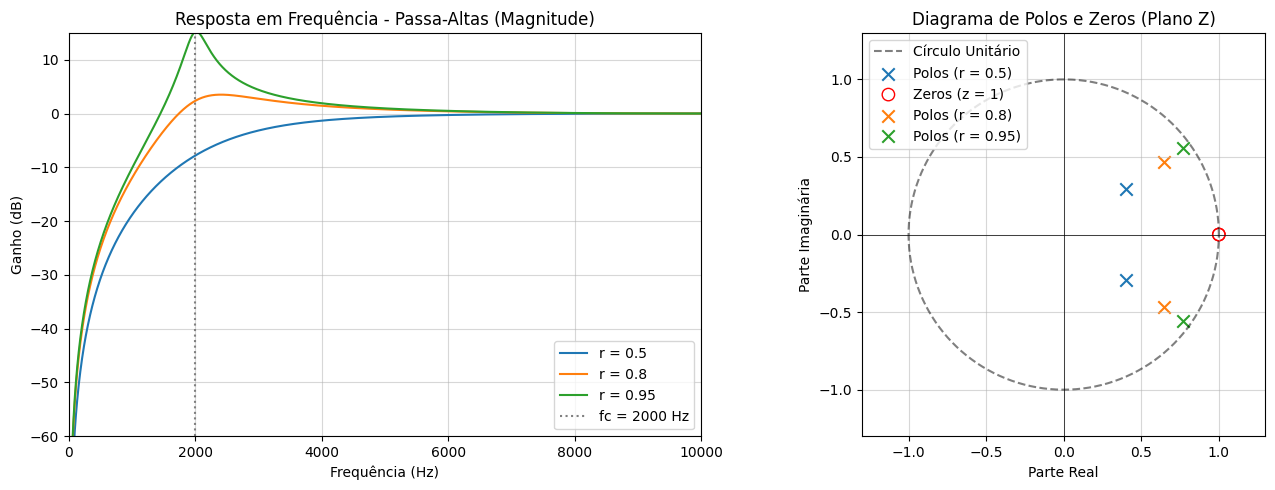

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Passa-Altas
fs = 20000  # Frequência de amostragem (Hz)
fc = 2000  # Frequência de corte / ressonância (Hz)
wc = 2 * np.pi * fc / fs  # Frequência digital normalizada (rad/amostra)

# Variável simbólica z para impressão da equação
z = sp.Symbol('z')

# Valores de r para investigação
valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário para o diagrama de polos e zeros
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Coeficientes do denominador de 2ª ordem
  m1 = -2 * r * np.cos(wc)
  m2 = r**2

  # Ganho de normalização K para ganho unitário (0 dB) em Nyquist (z = -1)
  K = (1 - m1 + m2) / 4

  # Numerador (dois zeros em z = 1) e Denominador
  num = K * np.array([1, -2, 1])
  den = np.array([1, m1, m2])

  # Montagem e impressão da equação H(z) com potências positivas de z
  # Corrigido: acessando cada índice individual do vetor 'num'
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (z = 1)',
    )

# Formatação do gráfico de Magnitude
ax1.set_title('Resposta em Frequência - Passa-Altas (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 2000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 15)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

Questão 1 - Letra c)


--- Função de Transferência H(z) para r = 0.5 ---
         2          
 0.3858⋅z  - 0.3858 
────────────────────
 2                  
z  + 0.5878⋅z + 0.25

--- Função de Transferência H(z) para r = 0.8 ---
         2          
 0.1806⋅z  - 0.1806 
────────────────────
 2                  
z  + 0.9405⋅z + 0.64

--- Função de Transferência H(z) para r = 0.95 ---
          2           
  0.0488⋅z  - 0.0488  
──────────────────────
 2                    
z  + 1.1168⋅z + 0.9025


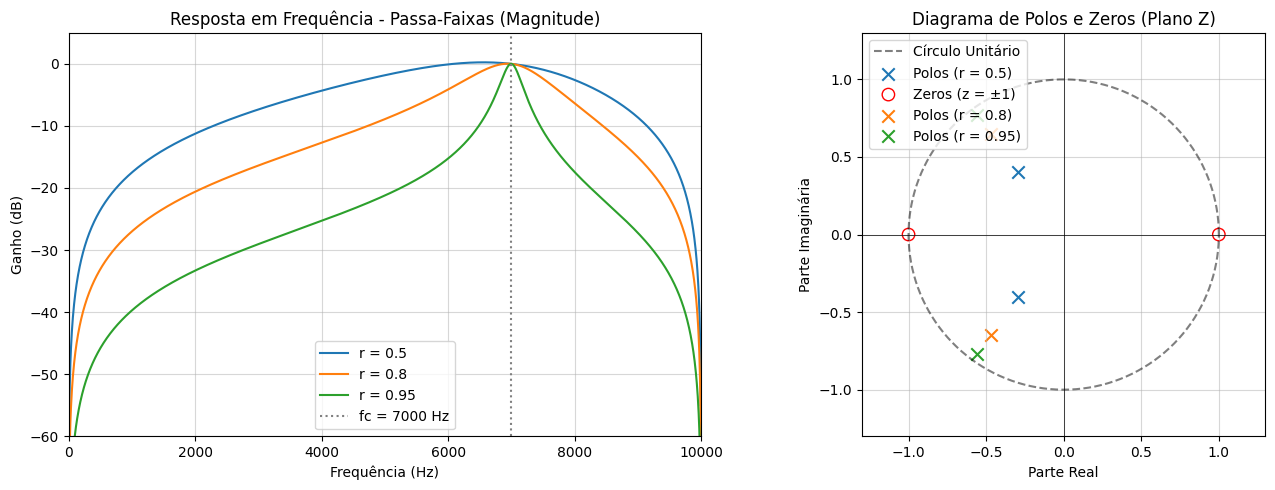

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Passa-Faixas
fs = 20000  # Frequência de amostragem (Hz)
fc = 7000  # Frequência central / ressonância (Hz)
wc = 2 * np.pi * fc / fs  # Frequência digital normalizada (rad/amostra)

# Variável simbólica z para impressão da equação
z = sp.Symbol('z')

# Valores de r para investigação
valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário para o diagrama de polos e zeros
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Coeficientes do denominador de 2ª ordem
  m1 = -2 * r * np.cos(wc)
  m2 = r**2

  # Ganho de normalização K para ganho unitário (0 dB) exato em z = e^(j*wc)
  z_wc = np.exp(1j * wc)
  ganho_sem_k = np.abs(
      (1 - z_wc**-2) / (1 + m1 * z_wc**-1 + m2 * z_wc**-2)
  )
  K = 1.0 / ganho_sem_k

  # Numerador (zeros em z = 1 e z = -1) e Denominador
  num = K * np.array([1, 0, -1])
  den = np.array([1, m1, m2])

  # Montagem e impressão da equação H(z) com potências positivas de z
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (z = ±1)',
    )

# Formatação do gráfico de Magnitude
ax1.set_title('Resposta em Frequência - Passa-Faixas (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 7000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 5)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Questão 1 - Letra d)


--- Função de Transferência H(z) para r = 0.5 ---
        2                    
0.8032⋅z  - 0.9443⋅z + 0.8032
─────────────────────────────
     2                       
    z  - 0.5878⋅z + 0.25     

--- Função de Transferência H(z) para r = 0.8 ---
        2                    
0.8485⋅z  - 0.9975⋅z + 0.8485
─────────────────────────────
     2                       
    z  - 0.9405⋅z + 0.64     

--- Função de Transferência H(z) para r = 0.95 ---
       2                   
0.953⋅z  - 1.1204⋅z + 0.953
───────────────────────────
   2                       
  z  - 1.1168⋅z + 0.9025   


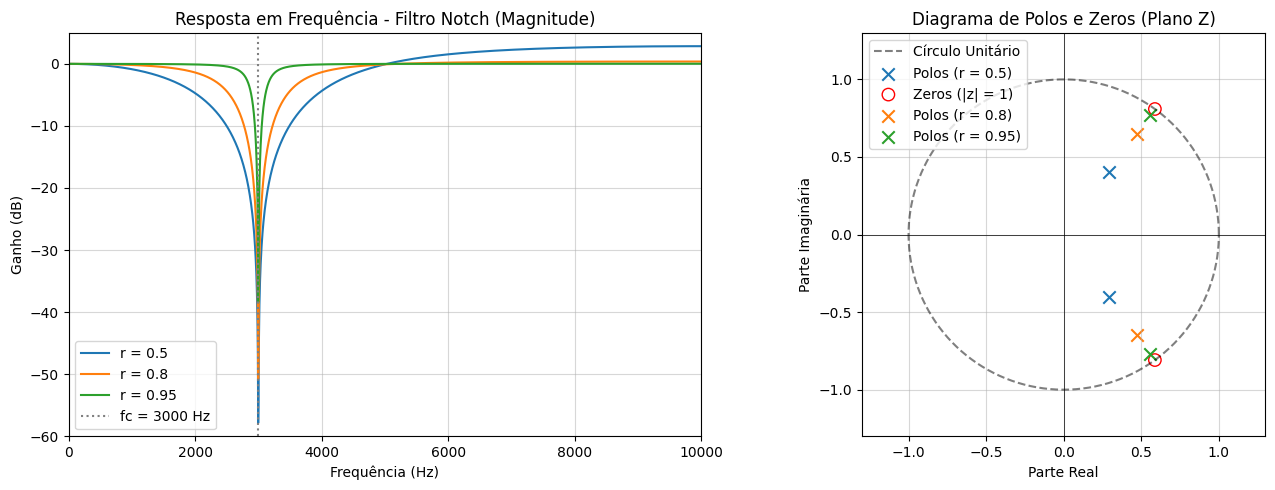

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Filtro Notch (Rejeita-Faixa)
fs = 20000
fc = 3000
wc = 2 * np.pi * fc / fs

# Variável simbólica z
z = sp.Symbol('z')

valores_r = [0.5, 0.8, 0.95]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  b1 = -2 * np.cos(wc)
  m1 = -2 * r * np.cos(wc)
  m2 = r**2
  K = (1 + m1 + m2) / (2 + b1)

  num = K * np.array([1, b1, 1])
  den = np.array([1, m1, m2])

  # Impressão com z positivo (z^2, z^1, z^0)
  num_sym = round(num[0], 4) * z**2 + round(num[1], 4) * z + round(num[2], 4)
  den_sym = z**2 + round(den[1], 4) * z + round(den[2], 4)
  H = num_sym / den_sym

  print(f'\n--- Função de Transferência H(z) para r = {r} ---')
  sp.pprint(H)

  # Resposta em Frequência
  w, h = signal.freqz(num, den, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num, den)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  if r == 0.5:
    ax2.scatter(
        np.real(zeros),
        np.imag(zeros),
        marker='o',
        facecolors='none',
        edgecolors='red',
        s=80,
        label='Zeros (|z| = 1)',
    )

ax1.set_title('Resposta em Frequência - Filtro Notch (Magnitude)')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc, color='gray', linestyle=':', label='fc = 3000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-60, 5)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.3, 1.3)
ax2.set_ylim(-1.3, 1.3)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Questão 2

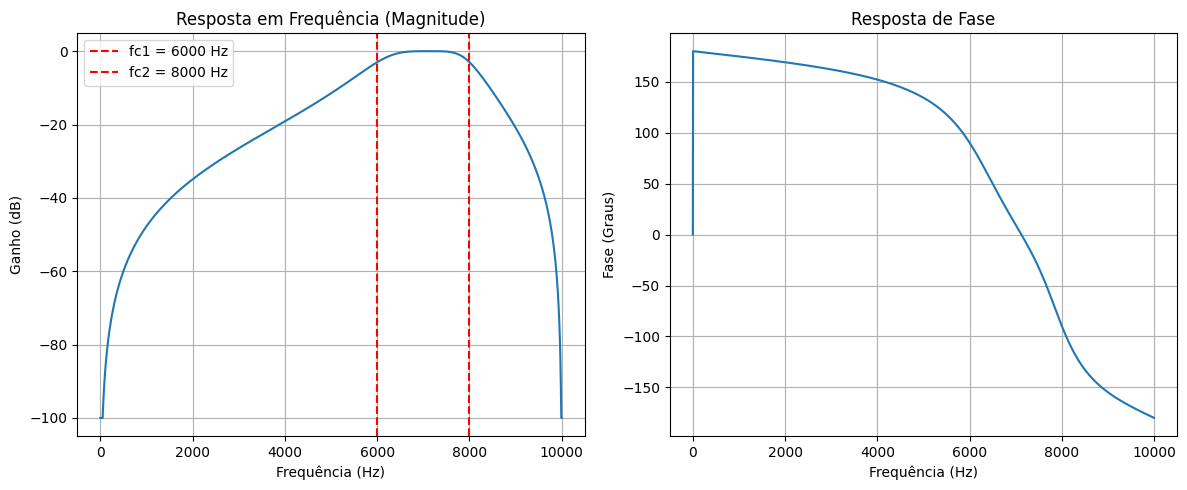

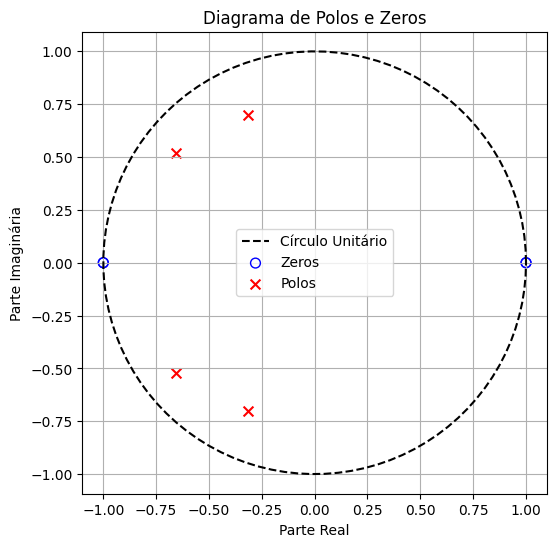

'\n\nComentários sobre os resultados:\n\n1. Resposta em Frequência:\n   O filtro projetado apresenta uma banda de passagem plana e bem definida entre fc1 = 6000 Hz e\n   fc2 = 8000 Hz (largura de banda de 2000 Hz centrada em 7000 Hz), com atenuação de -3 dB exatos\n   nas duas frequências de corte e decaimento acentuado nas bandas de rejeição.\n\n2. Diagrama de Polos e Zeros:\n   - Como utilizamos 2 blocos básicos de 2ª ordem em cascata (ordem 4 no total), o sistema possui\n     4 zeros (dois em z = 1 e dois em z = -1) e 2 pares de polos complexos conjugados localizados\n     estritamente dentro do círculo unitário, garantindo a estabilidade do filtro.\n   - Os dois pares de polos distribuem-se ao redor dos ângulos correspondentes a 6000 Hz e 8000 Hz,\n     sustentando o ganho plano em toda a faixa de passagem.\n\n3. Comparação com a Questão 1 (Letra c):\n   - Centro de frequência: Ambos os filtros estão centrados em 7000 Hz (média entre 6000 Hz e 8000 Hz).\n   - Seletividade e Banda P

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal

# Parâmetros do filtro
fs = 20000.0  # Frequência de amostragem (Hz)
fc1 = 6000.0  # Frequência de corte inferior (Hz)
fc2 = 8000.0  # Frequência de corte superior (Hz)
nyq = 0.5 * fs

# Normalização das frequências de corte
low = fc1 / nyq
high = fc2 / nyq

# Ajuste: order = 2 em passa-faixas resulta em 4ª ordem total (cascata de 2 blocos de 2ª ordem)
order = 2
sos = signal.butter(order, [low, high], btype='band', output='sos')

# 1. Resposta em Frequência
w, h = signal.sosfreqz(sos, worN=2000, fs=fs)

plt.figure(figsize=(12, 5))

# Gráfico da Magnitude
plt.subplot(1, 2, 1)
plt.plot(w, 20 * np.log10(np.maximum(abs(h), 1e-5)))
plt.title('Resposta em Frequência (Magnitude)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Ganho (dB)')
plt.grid(True)
plt.axvline(fc1, color='red', linestyle='--', label='fc1 = 6000 Hz')
plt.axvline(fc2, color='red', linestyle='--', label='fc2 = 8000 Hz')
plt.legend()

# Gráfico da Fase
plt.subplot(1, 2, 2)
plt.plot(w, np.angle(h) * 180 / np.pi)
plt.title('Resposta de Fase')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Fase (Graus)')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Diagramas de Polos e Zeros
# Extração de polos e zeros a partir de SOS
z, p, k = signal.sos2zpk(sos)

plt.figure(figsize=(6, 6))
# Círculo unitário
theta = np.linspace(0, 2 * np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo Unitário')

# Plot de polos (x) e zeros (o)
plt.scatter(
    np.real(z),
    np.imag(z),
    s=50,
    marker='o',
    facecolors='none',
    edgecolors='b',
    label='Zeros',
)
plt.scatter(np.real(p), np.imag(p), s=50, marker='x', color='r', label='Polos')

plt.title('Diagrama de Polos e Zeros')
plt.xlabel('Parte Real')
plt.ylabel('Parte Imaginária')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

# --- COMENTÁRIOS E COMPARAÇÃO ---
"""

Comentários sobre os resultados:

1. Resposta em Frequência:
   O filtro projetado apresenta uma banda de passagem plana e bem definida entre fc1 = 6000 Hz e
   fc2 = 8000 Hz (largura de banda de 2000 Hz centrada em 7000 Hz), com atenuação de -3 dB exatos
   nas duas frequências de corte e decaimento acentuado nas bandas de rejeição.

2. Diagrama de Polos e Zeros:
   - Como utilizamos 2 blocos básicos de 2ª ordem em cascata (ordem 4 no total), o sistema possui
     4 zeros (dois em z = 1 e dois em z = -1) e 2 pares de polos complexos conjugados localizados
     estritamente dentro do círculo unitário, garantindo a estabilidade do filtro.
   - Os dois pares de polos distribuem-se ao redor dos ângulos correspondentes a 6000 Hz e 8000 Hz,
     sustentando o ganho plano em toda a faixa de passagem.

3. Comparação com a Questão 1 (Letra c):
   - Centro de frequência: Ambos os filtros estão centrados em 7000 Hz (média entre 6000 Hz e 8000 Hz).
   - Seletividade e Banda Passante: Na Questão 1(c), o passa-faixas usava apenas um único bloco de
     2ª ordem (1 par de polos), gerando apenas um pico pontual em 7000 Hz, onde a largura de banda
     dependia do raio r (por exemplo, BW ≈ 3183 Hz para r = 0,5 e BW ≈ 318 Hz para r = 0,95). Nesta
     questão, a cascata de dois blocos de 2ª ordem permite controlar diretamente fc1 e fc2, criando
     uma banda passante plana de 2000 Hz com transições muito mais abruptas (maior seletividade).

"""


Questão 3


--- Função de Transferência Resultante H(z) (r = 0.75) ---
        4           3           2                   
0.5405⋅z  - 1.6834⋅z  + 2.2582⋅z  - 1.2699⋅z + 0.304
────────────────────────────────────────────────────
      4           3           2                     
 1.0⋅z  - 1.8901⋅z  + 1.7863⋅z  - 1.0632⋅z + 0.3164 


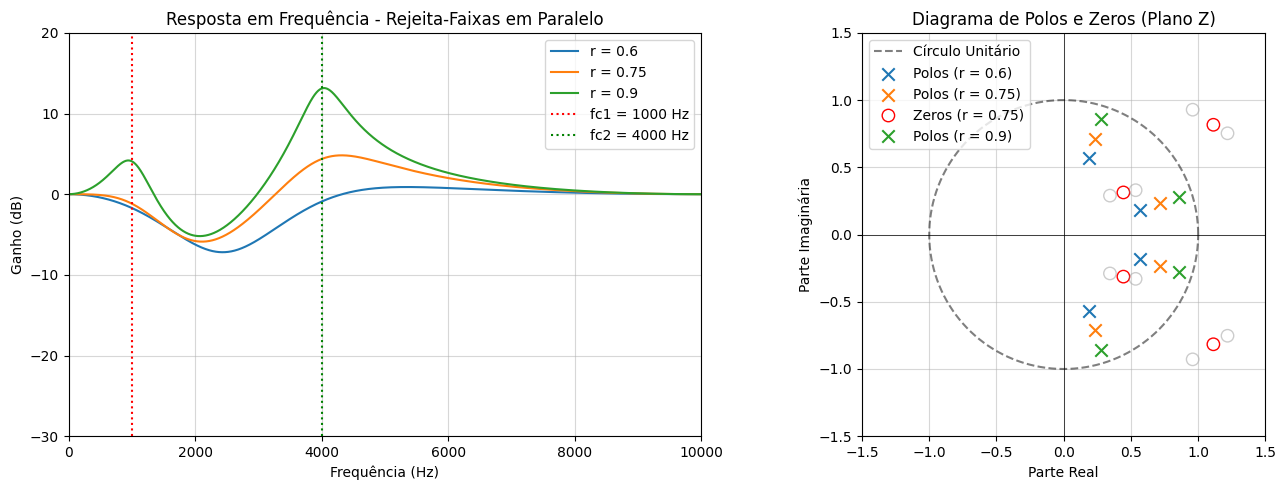

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
import sympy as sp

# Parâmetros do projeto: Rejeita-Faixas em Paralelo
fs = 20000.0  # Frequência de amostragem (Hz)
fc1 = 1000.0  # Frequência de corte inferior - Passa-Baixas (Hz)
fc2 = 4000.0  # Frequência de corte superior - Passa-Altas (Hz)

wc1 = 2 * np.pi * fc1 / fs
wc2 = 2 * np.pi * fc2 / fs

z = sp.Symbol('z')
valores_r = [0.6, 0.75, 0.9]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Círculo unitário
theta = np.linspace(0, 2 * np.pi, 300)
ax2.plot(
    np.cos(theta), np.sin(theta), 'k--', alpha=0.5, label='Círculo Unitário'
)

for r in valores_r:
  # Bloco 1: Passa-Baixas de 2ª ordem (fc1 = 1000 Hz)
  m1_pb = -2 * r * np.cos(wc1)
  m2_pb = r**2
  K_pb = (1 + m1_pb + m2_pb) / 4
  num_pb = K_pb * np.array([1, 2, 1])
  den_pb = np.array([1, m1_pb, m2_pb])

  # Bloco 2: Passa-Altas de 2ª ordem (fc2 = 4000 Hz)
  m1_pa = -2 * r * np.cos(wc2)
  m2_pa = r**2
  K_pa = (1 - m1_pa + m2_pa) / 4
  num_pa = K_pa * np.array([1, -2, 1])
  den_pa = np.array([1, m1_pa, m2_pa])

  # Associação em Paralelo: H(z) = H_pb(z) + H_pa(z)
  num_total = np.convolve(num_pb, den_pa) + np.convolve(num_pa, den_pb)
  den_total = np.convolve(den_pb, den_pa)

  if r == 0.75:
    num_sym = sum(
        round(num_total[i], 4) * z ** (4 - i) for i in range(len(num_total))
    )
    den_sym = sum(
        round(den_total[i], 4) * z ** (4 - i) for i in range(len(den_total))
    )
    print(f'\n--- Função de Transferência Resultante H(z) (r = {r}) ---')
    sp.pprint(num_sym / den_sym)

  # 1. Resposta em Frequência
  w, h = signal.freqz(num_total, den_total, worN=2048, fs=fs)
  ax1.plot(w, 20 * np.log10(np.abs(h) + 1e-12), label=f'r = {r}')

  # 2. Diagrama de Polos e Zeros
  zeros, polos, _ = signal.tf2zpk(num_total, den_total)
  ax2.scatter(
      np.real(polos),
      np.imag(polos),
      marker='x',
      s=80,
      label=f'Polos (r = {r})',
  )
  ax2.scatter(
      np.real(zeros),
      np.imag(zeros),
      marker='o',
      facecolors='none',
      edgecolors='red' if r == 0.75 else 'gray',
      alpha=1.0 if r == 0.75 else 0.4,
      s=80,
      label='Zeros (r = 0.75)' if r == 0.75 else '',
  )

# Formatação do gráfico de Magnitude (limite superior ampliado para 20 dB)
ax1.set_title('Resposta em Frequência - Rejeita-Faixas em Paralelo')
ax1.set_xlabel('Frequência (Hz)')
ax1.set_ylabel('Ganho (dB)')
ax1.axvline(fc1, color='red', linestyle=':', label='fc1 = 1000 Hz')
ax1.axvline(fc2, color='green', linestyle=':', label='fc2 = 4000 Hz')
ax1.set_xlim(0, fs / 2)
ax1.set_ylim(-30, 20)
ax1.grid(True, which='both', alpha=0.5)
ax1.legend()

# Formatação do Diagrama de Polos e Zeros (margem ampliada para 1.5)
ax2.set_title('Diagrama de Polos e Zeros (Plano Z)')
ax2.set_xlabel('Parte Real')
ax2.set_ylabel('Parte Imaginária')
ax2.axhline(0, color='black', linewidth=0.5)
ax2.axvline(0, color='black', linewidth=0.5)
ax2.set_aspect('equal')
ax2.set_xlim(-1.5, 1.5)
ax2.set_ylim(-1.5, 1.5)
ax2.grid(True, alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()


Síntese comparativa. Enquanto o filtro Notch é ideal para eliminar uma única frequência interferente (como um ruído senoidal de rede) sem alterar o restante do espectro, o rejeita-faixas em paralelo permite suprimir toda uma região espectral extensa 1000 Hz a 4000 Hz, ao custo de maior ordem computacional e de uma atenuação finita na banda rejeitada (já que os zeros não repousam exatamente sobre o círculo unitário).

Questão 4

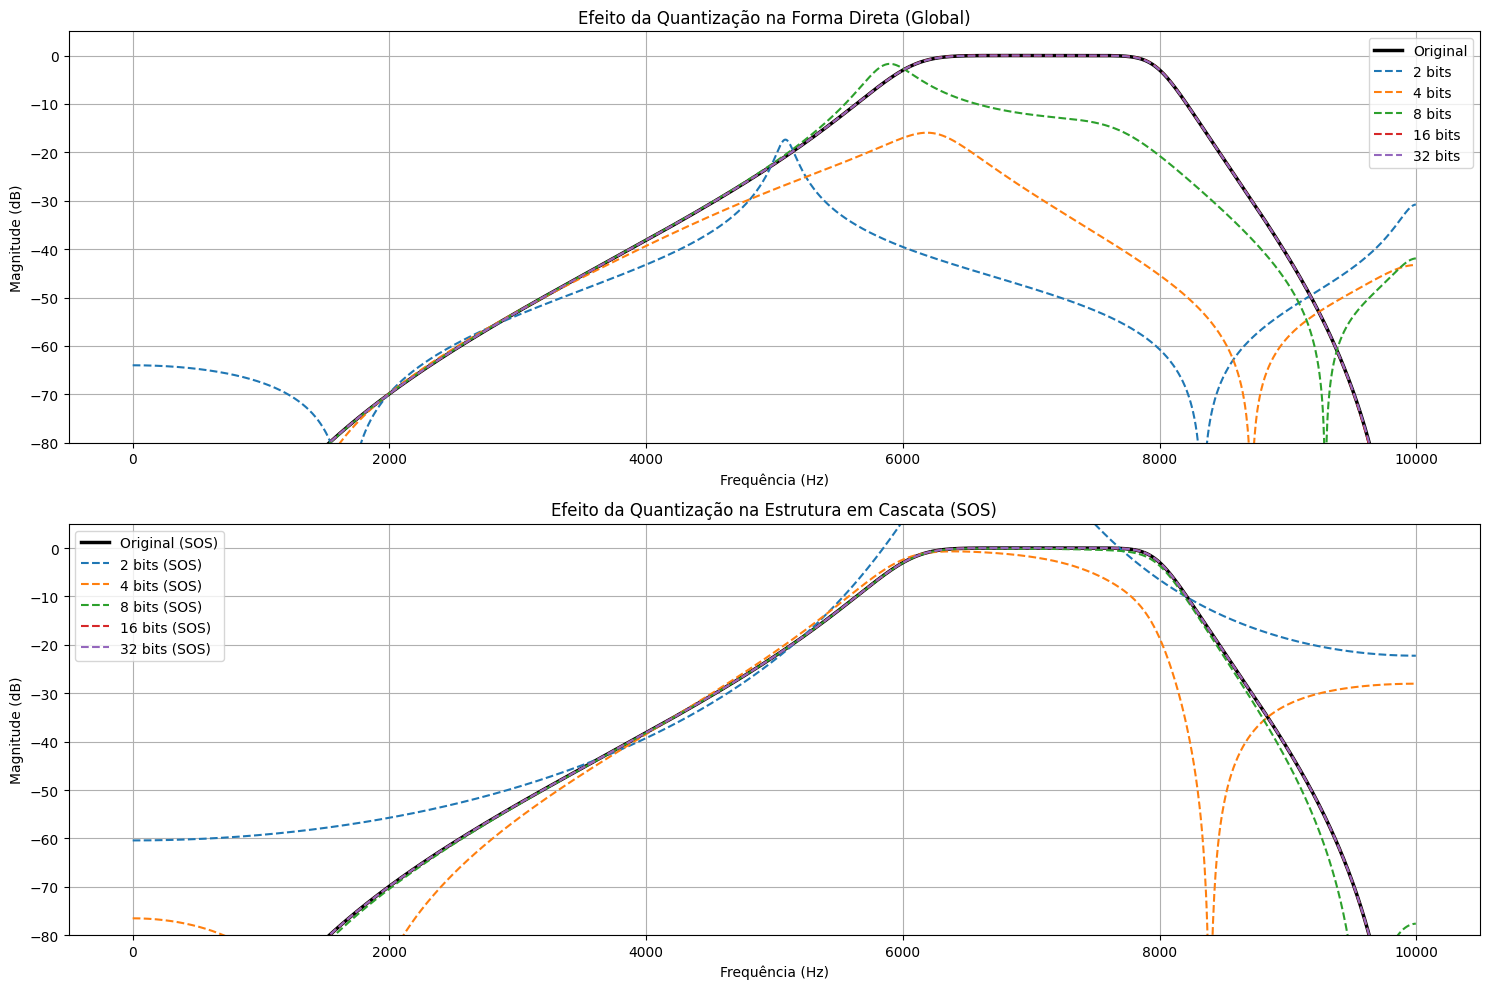

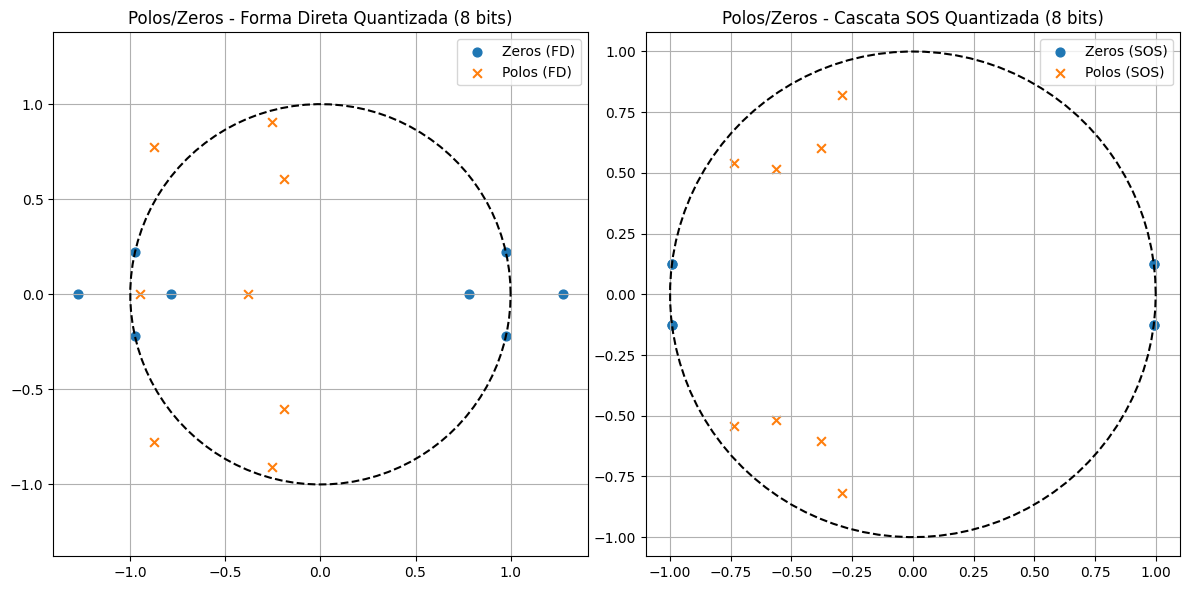

'\nComentários sobre os resultados da quantização:\n\n1. Sensibilidade ao Comprimento da Palavra (bits):\n   - Com 32 e 16 bits, ambas as estruturas se comportam de maneira ideal e estável.\n   - Com 8 bits, notamos pequenas distorções na banda de passagem, contudo, a estrutura em cascata SOS\n     mantém o formato original do filtro de maneira visivelmente superior à Forma Direta global.\n   - Com 4 e 2 bits, as características passa-faixas são completamente degradadas em ambas as implementações,\n     indicando que o mínimo de bits de precisão aceitável para o projeto deste filtro em ponto fixo é de cerca de 8 bits.\n\n2. Estabilidade e Diagrama de Polos e Zeros:\n   - Na Forma Direta com 8 bits, pequenos desvios nos coeficientes deslocam de maneira desproporcional os polos.\n     Isso ocorre devido ao fato de que, em ordens maiores, as raízes do polinômio do denominador (polos)\n     são altamente sensíveis às variações dos seus coeficientes (fenômeno conhecido como Sensibilidade de

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Parâmetros originais do filtro (Questão 2)
fs = 20000.0
fc1 = 6000.0
fc2 = 8000.0
nyq = 0.5 * fs
low = fc1 / nyq
high = fc2 / nyq
order = 4

# Filtro original em representação SOS e Forma Direta (b, a)
sos_orig = signal.butter(order, [low, high], btype='band', output='sos')
b_orig, a_orig = signal.butter(order, [low, high], btype='band', output='ba')

# Função de quantização uniforme de ponto fixo
def quantize_coefficients(coefs, bits):
    if bits >= 32:
        return coefs.copy()

    max_val = np.max(np.abs(coefs))
    if max_val == 0:
        return coefs

    # Normaliza os coeficientes na faixa [-1, 1]
    norm_coefs = coefs / max_val

    # Quantiza na faixa discreta para os bits fornecidos
    levels = 2**(bits - 1) - 1
    quant_coefs = np.round(norm_coefs * levels) / levels

    # Retorna à escala original
    return quant_coefs * max_val

bits_list = [2, 4, 8, 16, 32]

# 1. Resposta em frequência para quantização na Forma Direta
plt.figure(figsize=(15, 10))

plt.subplot(2, 1, 1)
# Resposta original
w, h_orig = signal.freqz(b_orig, a_orig, worN=2000, fs=fs)
plt.plot(w, 20 * np.log10(np.maximum(abs(h_orig), 1e-5)), 'k-', linewidth=2.5, label='Original')

for b_val in bits_list:
    # Na Forma Direta, o termo a_orig[0] é sempre 1.0. Vamos preservá-lo e quantizar o resto.
    b_q = quantize_coefficients(b_orig, b_val)
    a_q = a_orig.copy()
    a_q[1:] = quantize_coefficients(a_orig[1:], b_val)

    w, h_q = signal.freqz(b_q, a_q, worN=2000, fs=fs)
    plt.plot(w, 20 * np.log10(np.maximum(abs(h_q), 1e-5)), '--', label=f'{b_val} bits')

plt.title('Efeito da Quantização na Forma Direta (Global)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend()

# 2. Resposta em frequência para quantização em Cascata (SOS)
plt.subplot(2, 1, 2)
w, h_sos_orig = signal.sosfreqz(sos_orig, worN=2000, fs=fs)
plt.plot(w, 20 * np.log10(np.maximum(abs(h_sos_orig), 1e-5)), 'k-', linewidth=2.5, label='Original (SOS)')

for b_val in bits_list:
    sos_q = sos_orig.copy()
    for i in range(sos_q.shape[0]):
        # Quantiza separadamente o numerador (b0, b1, b2)
        sos_q[i, 0:3] = quantize_coefficients(sos_q[i, 0:3], b_val)
        # No denominador, o termo a0 (sos_q[i, 3]) deve ser sempre exatamente 1.0
        sos_q[i, 3] = 1.0
        # Quantizamos apenas os coeficientes de realimentação (a1, a2)
        sos_q[i, 4:6] = quantize_coefficients(sos_q[i, 4:6], b_val)

    w, h_sos_q = signal.sosfreqz(sos_q, worN=2000, fs=fs)
    plt.plot(w, 20 * np.log10(np.maximum(abs(h_sos_q), 1e-5)), '--', label=f'{b_val} bits (SOS)')

plt.title('Efeito da Quantização na Estrutura em Cascata (SOS)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim([-80, 5])
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# --- DIAGRAMA DE POLOS E ZEROS DOS SISTEMAS QUANTIZADOS (Comparativo 8 bits) ---
plt.figure(figsize=(12, 6))

# Polos/Zeros Forma Direta com 8 bits
b_q8 = quantize_coefficients(b_orig, 8)
a_q8 = a_orig.copy()
a_q8[1:] = quantize_coefficients(a_orig[1:], 8)
z_fd, p_fd, _ = signal.tf2zpk(b_q8, a_q8)

# Polos/Zeros SOS com 8 bits
sos_q8 = sos_orig.copy()
for i in range(sos_q8.shape[0]):
    sos_q8[i, 0:3] = quantize_coefficients(sos_q8[i, 0:3], 8)
    sos_q8[i, 3] = 1.0
    sos_q8[i, 4:6] = quantize_coefficients(sos_q8[i, 4:6], 8)
z_sos, p_sos, _ = signal.sos2zpk(sos_q8)

theta = np.linspace(0, 2*np.pi, 100)

# Subplot Forma Direta
plt.subplot(1, 2, 1)
plt.plot(np.cos(theta), np.sin(theta), 'k--')
plt.scatter(np.real(z_fd), np.imag(z_fd), s=40, marker='o', label='Zeros (FD)')
plt.scatter(np.real(p_fd), np.imag(p_fd), s=40, marker='x', label='Polos (FD)')
plt.title('Polos/Zeros - Forma Direta Quantizada (8 bits)')
plt.axis('equal')
plt.grid(True)
plt.legend()

# Subplot SOS
plt.subplot(1, 2, 2)
plt.plot(np.cos(theta), np.sin(theta), 'k--')
plt.scatter(np.real(z_sos), np.imag(z_sos), s=40, marker='o', label='Zeros (SOS)')
plt.scatter(np.real(p_sos), np.imag(p_sos), s=40, marker='x', label='Polos (SOS)')
plt.title('Polos/Zeros - Cascata SOS Quantizada (8 bits)')
plt.axis('equal')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# --- COMENTÁRIOS ---
"""
Comentários sobre os resultados da quantização:

1. Sensibilidade ao Comprimento da Palavra (bits):
   - Com 32 e 16 bits, ambas as estruturas se comportam de maneira ideal e estável.
   - Com 8 bits, notamos pequenas distorções na banda de passagem, contudo, a estrutura em cascata SOS
     mantém o formato original do filtro de maneira visivelmente superior à Forma Direta global.
   - Com 4 e 2 bits, as características passa-faixas são completamente degradadas em ambas as implementações,
     indicando que o mínimo de bits de precisão aceitável para o projeto deste filtro em ponto fixo é de cerca de 8 bits.

2. Estabilidade e Diagrama de Polos e Zeros:
   - Na Forma Direta com 8 bits, pequenos desvios nos coeficientes deslocam de maneira desproporcional os polos.
     Isso ocorre devido ao fato de que, em ordens maiores, as raízes do polinômio do denominador (polos)
     são altamente sensíveis às variações dos seus coeficientes (fenômeno conhecido como Sensibilidade de Wilkinson).
   - Na estrutura SOS, ao decompor o sistema em seções de 2ª ordem, isolamos as raízes em polinômios de baixo grau,
     o que atenua significativamente essa sensibilidade. Os polos do SOS mantêm-se em posições praticamente idênticas
     às originais e em áreas seguras dentro do círculo unitário, assegurando a estabilidade.
"""

Questão 5

Por favor, faça o upload do arquivo 'handel.wav':


Saving handel.wav to handel.wav


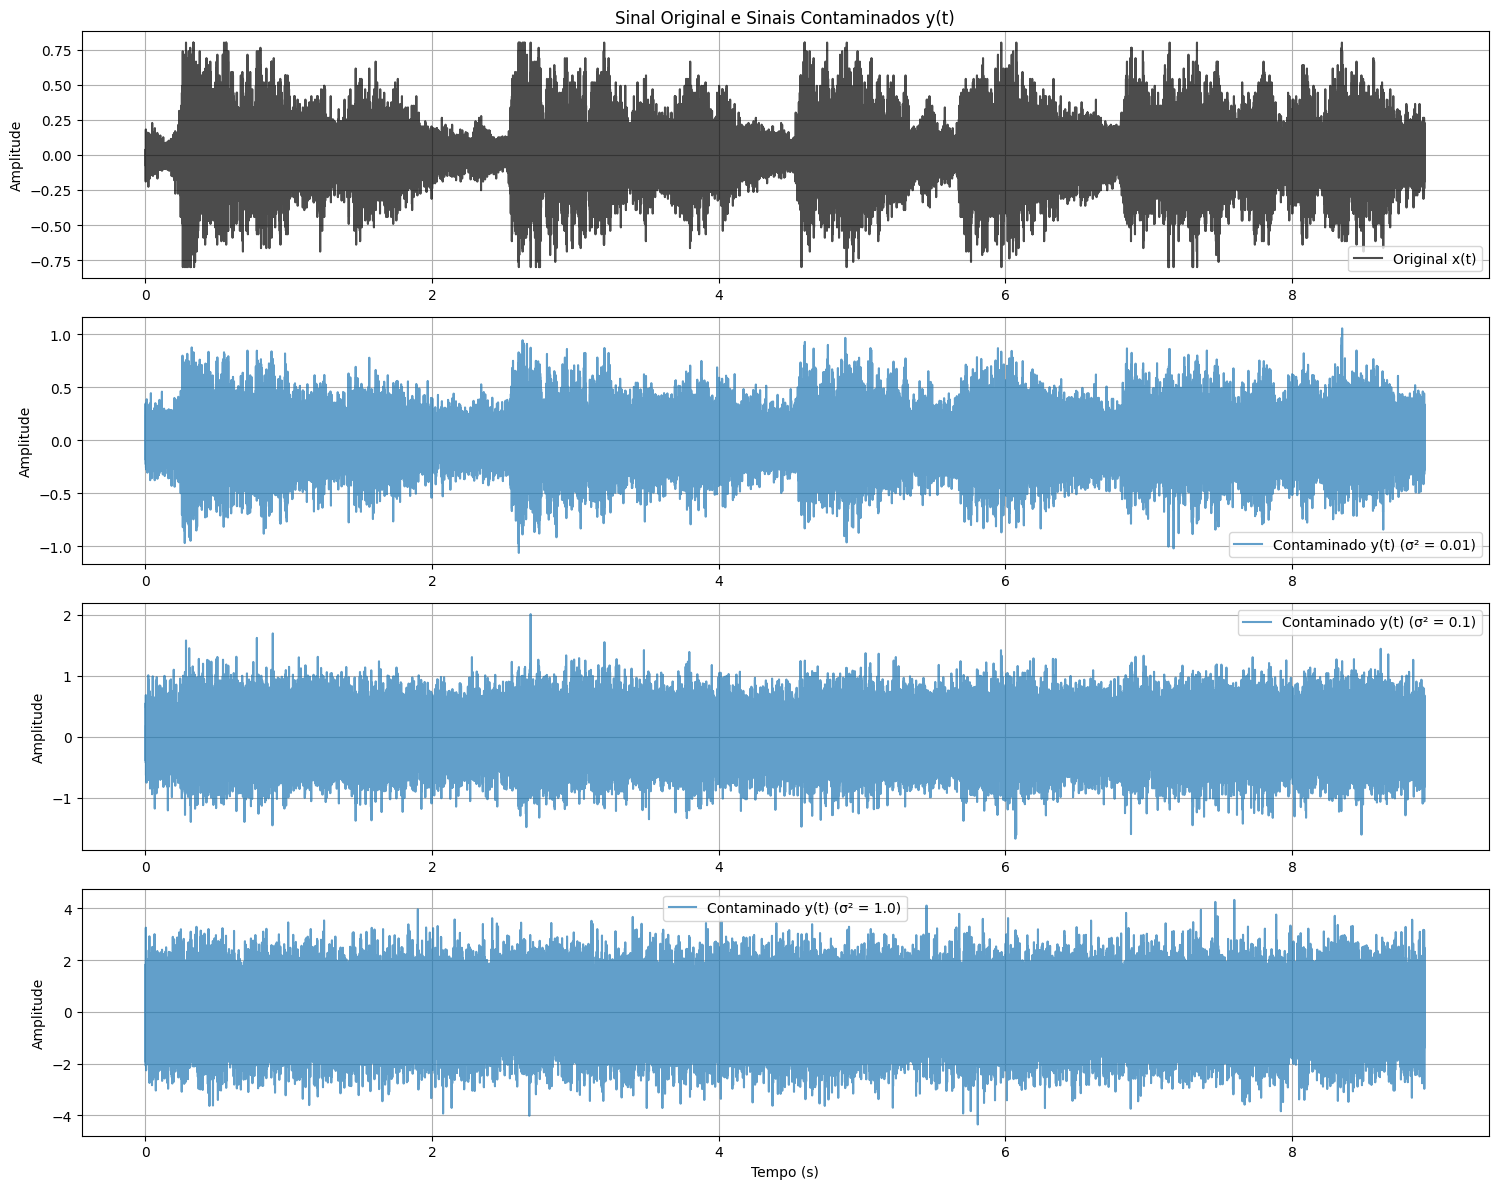

Sinais gerados e salvos no dicionário 'y_signals' com sucesso!


In [1]:
from google.colab import files
import io
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile

print("Por favor, faça o upload do arquivo 'handel.wav':")
uploaded = files.upload()

if 'handel.wav' in uploaded:
    # Carrega o áudio de entrada x(t)
    fs_audio, x = wavfile.read(io.BytesIO(uploaded['handel.wav']))

    # Normaliza o sinal de áudio se necessário
    if x.dtype == np.int16:
        x = x / 32768.0
    elif x.dtype == np.int32:
        x = x / 2147483648.0

    N = len(x)
    t = np.arange(N) / fs_audio

    # Modelagem das interferências senoidais
    # 0.05 * cos(200 * pi * t) -> frequência de 100 Hz
    # 0.075 * sin(4000 * pi * t) -> frequência de 2000 Hz
    interf_low = 0.05 * np.cos(200 * np.pi * t)
    interf_high = 0.075 * np.sin(4000 * np.pi * t)

    variances = [1e-2, 1e-1, 1.0]
    y_signals = {}

    # Plot do sinal original e das versões ruidosas
    plt.figure(figsize=(15, 12))

    plt.subplot(4, 1, 1)
    plt.plot(t, x, 'k-', alpha=0.7, label='Original x(t)')
    plt.title('Sinal Original e Sinais Contaminados y(t)')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.legend()

    # Geração dos sinais corrompidos
    for i, var in enumerate(variances, start=2):
        std_dev = np.sqrt(var)
        noise = np.random.normal(0, std_dev, N)

        # y(t) = x(t) + 0.05*cos(200*pi*t) + 0.075*sin(4000*pi*t) + n(t)
        y = x + interf_low + interf_high + noise
        y_signals[var] = y

        plt.subplot(4, 1, i)
        plt.plot(t, y, alpha=0.7, label=f'Contaminado y(t) (σ² = {var})')
        plt.ylabel('Amplitude')
        plt.grid(True)
        plt.legend()

    plt.xlabel('Tempo (s)')
    plt.tight_layout()
    plt.show()
    print("Sinais gerados e salvos no dicionário 'y_signals' com sucesso!")
else:
    print("Erro: Por favor, envie exatamente o arquivo com o nome 'handel.wav'.")

Questão 5 a)

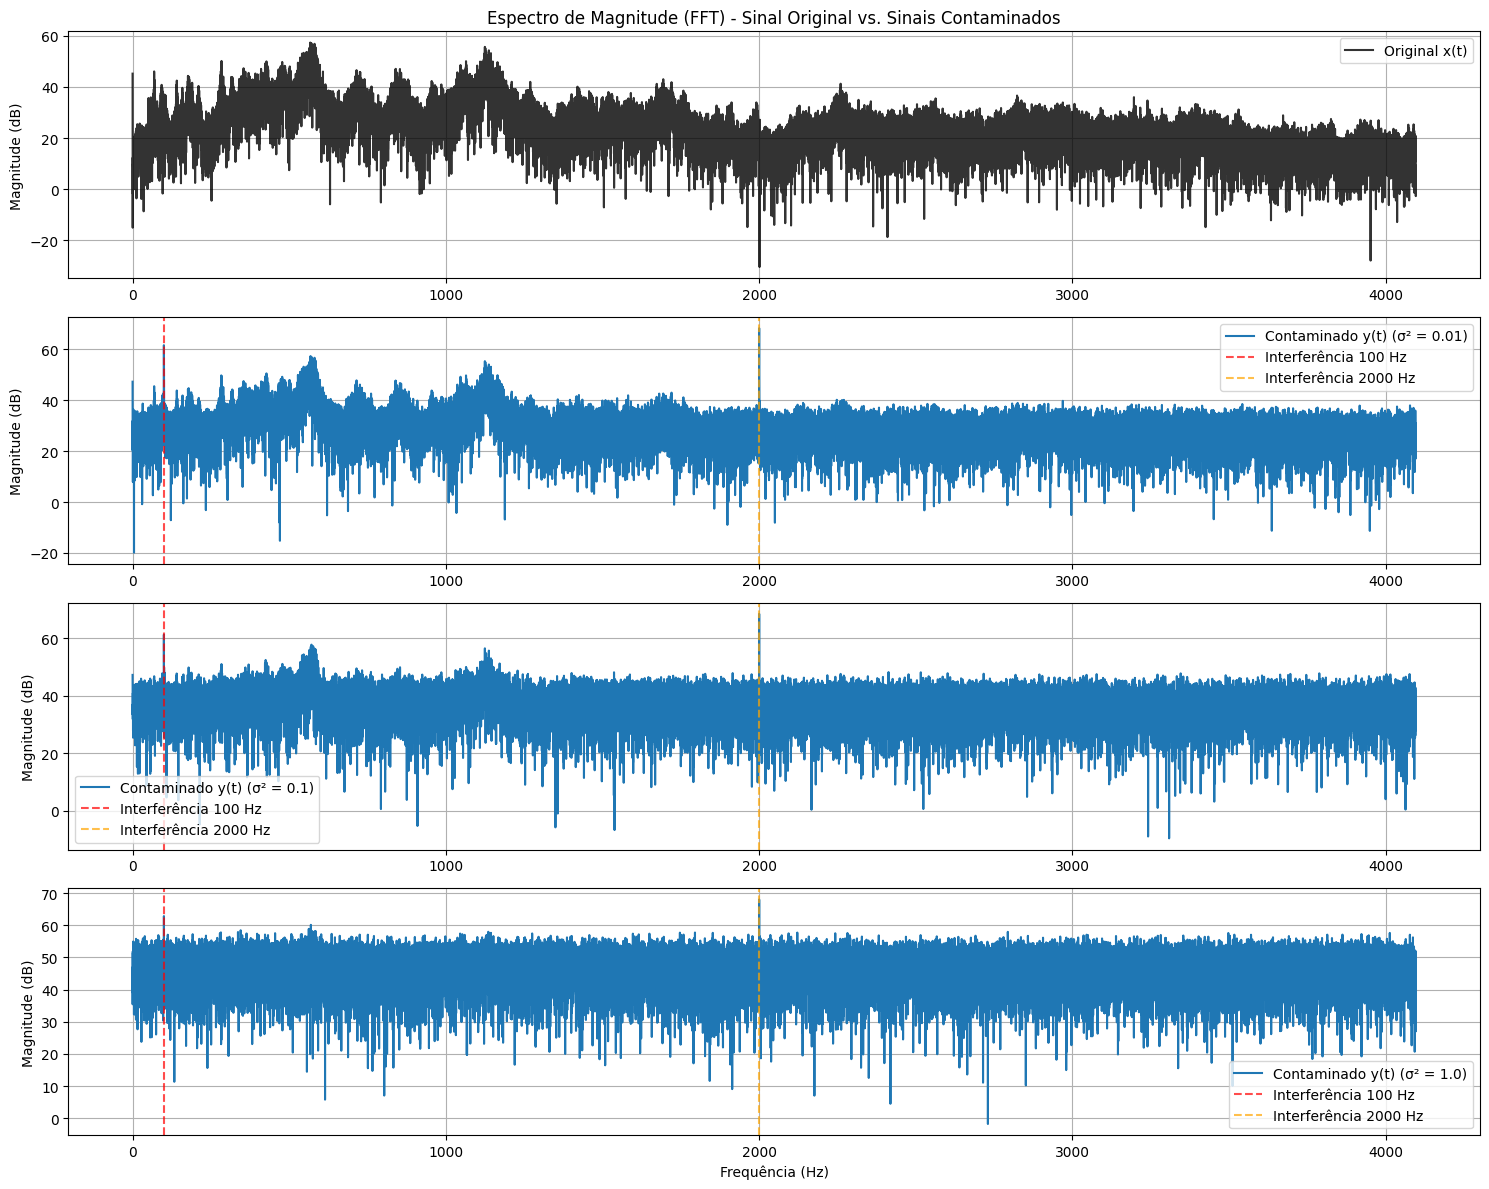


Comentários sobre os Resultados Obtidos (Questão 5a):

1. Comparação no Domínio do Tempo:
   - Para σ² = 1e-2, o sinal de áudio original ainda é reconhecível visualmente no domínio do tempo,
     embora a interferência de alta frequência (2000 Hz) adicione uma oscilação perceptível sobre o sinal.
   - Para σ² = 1e-1 e 1.0, o ruído gaussiano domina completamente a forma de onda temporal,
     tornando impossível distinguir as características do áudio original a olho nu.

2. Comparação no Domínio da Frequência:
   - No espectro do sinal original, a energia está distribuída principalmente nas baixas e médias frequências.
   - Nos espectros dos sinais contaminados, as interferências de 100 Hz e 2000 Hz aparecem nitidamente como picos
     estreitos e proeminentes sobressaindo da assinatura espectral do áudio.
   - Conforme a variância do ruído branco aumenta (de 1e-2 para 1.0), o patamar de ruído de fundo (noise floor)
     sobe uniformemente em todas as frequências. Com σ² = 1.0, o ruído

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Cálculo da frequência correspondente para cada ponto da FFT unilateral
freqs = np.fft.rfftfreq(N, d=1/fs_audio)

plt.figure(figsize=(15, 12))

# 1. Espectro do Sinal Original x(t)
fft_x = np.fft.rfft(x)
plt.subplot(4, 1, 1)
plt.plot(freqs, 20 * np.log10(np.maximum(np.abs(fft_x), 1e-5)), 'k-', alpha=0.8, label='Original x(t)')
plt.title('Espectro de Magnitude (FFT) - Sinal Original vs. Sinais Contaminados')
plt.ylabel('Magnitude (dB)')
plt.grid(True)
plt.legend()

# 2. Espectro para cada nível de ruído em y(t)
for i, var in enumerate(variances, start=2):
    y_current = y_signals[var]
    fft_y = np.fft.rfft(y_current)

    plt.subplot(4, 1, i)
    plt.plot(freqs, 20 * np.log10(np.maximum(np.abs(fft_y), 1e-5)), label=f'Contaminado y(t) (σ² = {var})')

    # Destaque visual das componentes interferentes em 100 Hz e 2000 Hz
    plt.axvline(100, color='red', linestyle='--', alpha=0.7, label='Interferência 100 Hz')
    plt.axvline(2000, color='orange', linestyle='--', alpha=0.7, label='Interferência 2000 Hz')

    plt.ylabel('Magnitude (dB)')
    plt.grid(True)
    plt.legend()

plt.xlabel('Frequência (Hz)')
plt.tight_layout()
plt.show()

# --- COMENTÁRIOS E AVALIAÇÃO SUBJETIVA ---
print("""
Comentários sobre os Resultados Obtidos (Questão 5a):

1. Comparação no Domínio do Tempo:
   - Para σ² = 1e-2, o sinal de áudio original ainda é reconhecível visualmente no domínio do tempo,
     embora a interferência de alta frequência (2000 Hz) adicione uma oscilação perceptível sobre o sinal.
   - Para σ² = 1e-1 e 1.0, o ruído gaussiano domina completamente a forma de onda temporal,
     tornando impossível distinguir as características do áudio original a olho nu.

2. Comparação no Domínio da Frequência:
   - No espectro do sinal original, a energia está distribuída principalmente nas baixas e médias frequências.
   - Nos espectros dos sinais contaminados, as interferências de 100 Hz e 2000 Hz aparecem nitidamente como picos
     estreitos e proeminentes sobressaindo da assinatura espectral do áudio.
   - Conforme a variância do ruído branco aumenta (de 1e-2 para 1.0), o patamar de ruído de fundo (noise floor)
     sobe uniformemente em todas as frequências. Com σ² = 1.0, o ruído cobre quase todo o espectro do sinal útil,
     mas os picos senoidais ainda são visíveis devido ao seu caráter puramente tonal de banda estreita.

3. Avaliação Subjetiva do Áudio y(t):
   - Com σ² = 1e-2: Ouve-se a música de fundo ("Handel") com um zumbido grave contínuo de 100 Hz (semelhante ao 'hum' da rede elétrica)
     e um apito agudo em 2000 Hz, acompanhados por um chiado leve.
   - Com σ² = 1e-1: O chiado (ruído de fundo) fica muito forte, obscurecendo partes mais suaves da música,
     embora o tom de 2000 Hz e o zumbido ainda sejam claramente audíveis.
   - Com σ² = 1.0: O ruído estático torna-se ensurdecedor. A música é praticamente indetectável, sendo perceptível
     apenas o forte ruído branco de fundo e os dois tons espúrios (100 Hz e 2000 Hz) que se sobressaem do ruído.
""")

Questão 5 b)

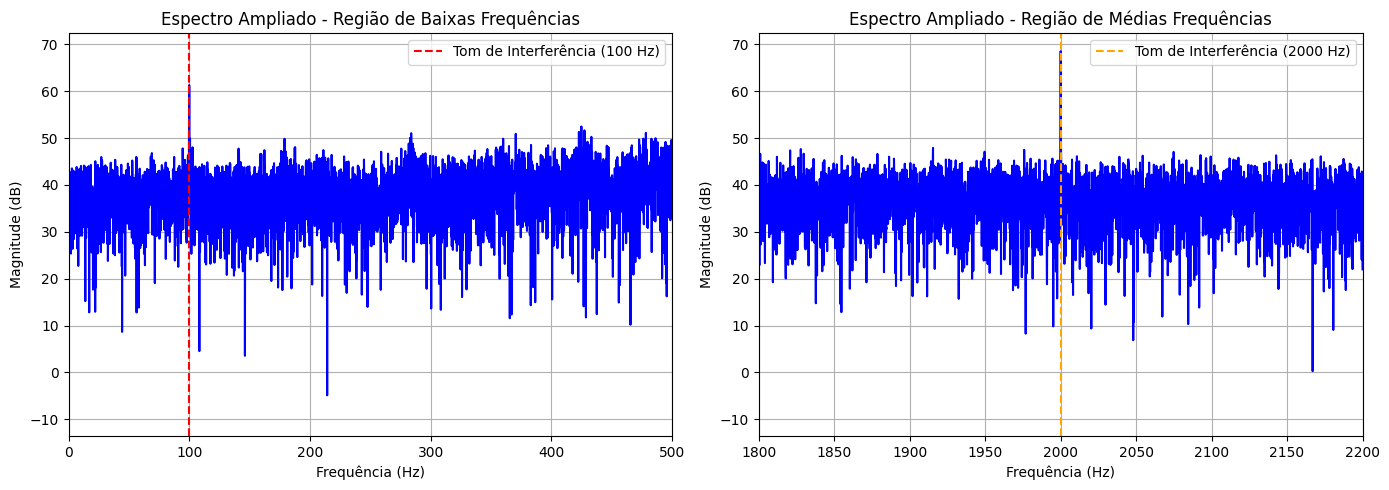


ANÁLISE ESPECTRAL E ESTRATÉGIAS DE FILTRAGEM (QUESTÃO 5b)

1. Componentes Removidos com Filtros NOTCH (Rejeita-Faixa Estrito):
   - A interferência de 100 Hz é ideal para remoção com um filtro Notch digital de banda estreita.
     Por estar em uma frequência extremamente baixa e específica, um Notch muito agudo consegue
     remover a interferência senoidal sem degradar de forma relevante a energia musical vizinha.
   - A interferência de 2000 Hz também pode ser atenuada de forma muito localizada por um filtro Notch,
     preservando os componentes espectrais do sinal original 'handel.wav' ao redor desta faixa.

2. Demandas para Filtros Passa-Baixas, Passa-Altas ou Passa-Faixas:
   - Filtro Passa-Altas: Pode ser usado alternativamente para remover a componente de 100 Hz,
     mas removeria também todo o conteúdo sub-grave musical legítimo abaixo dessa frequência.
   - Filtro Passa-Baixas (LPF): Como a maior parte da energia útil do áudio clássico 'handel.wav'
     concentra-se abaixo 

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Vamos analisar o espectro de magnitude detalhadamente focado nas interferências
freqs = np.fft.rfftfreq(N, d=1/fs_audio)
fft_y_med = np.abs(np.fft.rfft(y_signals[0.1])) # Usando variância moderada σ² = 0.1 para análise

plt.figure(figsize=(14, 5))

# Zoom na região de baixa frequência (Interferência de 100 Hz)
plt.subplot(1, 2, 1)
plt.plot(freqs, 20 * np.log10(np.maximum(fft_y_med, 1e-5)), color='blue')
plt.axvline(100, color='red', linestyle='--', label='Tom de Interferência (100 Hz)')
plt.xlim([0, 500])
plt.title('Espectro Ampliado - Região de Baixas Frequências')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.grid(True)
plt.legend()

# Zoom na região da segunda interferência (2000 Hz)
plt.subplot(1, 2, 2)
plt.plot(freqs, 20 * np.log10(np.maximum(fft_y_med, 1e-5)), color='blue')
plt.axvline(2000, color='orange', linestyle='--', label='Tom de Interferência (2000 Hz)')
plt.xlim([1800, 2200])
plt.title('Espectro Ampliado - Região de Médias Frequências')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# --- TEXTO DE ANÁLISE SISTÊMICA ---
print("""
=========================================================================================
ANÁLISE ESPECTRAL E ESTRATÉGIAS DE FILTRAGEM (QUESTÃO 5b)
=========================================================================================

1. Componentes Removidos com Filtros NOTCH (Rejeita-Faixa Estrito):
   - A interferência de 100 Hz é ideal para remoção com um filtro Notch digital de banda estreita.
     Por estar em uma frequência extremamente baixa e específica, um Notch muito agudo consegue
     remover a interferência senoidal sem degradar de forma relevante a energia musical vizinha.
   - A interferência de 2000 Hz também pode ser atenuada de forma muito localizada por um filtro Notch,
     preservando os componentes espectrais do sinal original 'handel.wav' ao redor desta faixa.

2. Demandas para Filtros Passa-Baixas, Passa-Altas ou Passa-Faixas:
   - Filtro Passa-Altas: Pode ser usado alternativamente para remover a componente de 100 Hz,
     mas removeria também todo o conteúdo sub-grave musical legítimo abaixo dessa frequência.
   - Filtro Passa-Baixas (LPF): Como a maior parte da energia útil do áudio clássico 'handel.wav'
     concentra-se abaixo de ~3.5 kHz, um filtro LPF com frequência de corte próxima a 3.5 kHz
     removeria ruídos brancos de altíssima frequência que estão fora da banda útil do áudio original.
   - Filtro Passa-Faixas (BPF): O filtro passa-faixas Butterworth de 4ª ordem projetado nas Questões 2/3
     (com banda de passagem de 6000 Hz a 8000 Hz) isolará estritamente essa banda específica. Ele
     eliminará naturalmente a interferência de 100 Hz, a de 2000 Hz e o ruído fora dessa faixa.

3. Limitações Impostas pela Presença do Ruído Branco Gaussiano:
   - Ao contrário das interferências senoidais (que concentram sua energia em picos de frequência pontuais),
     o ruído branco possui Densidade Espectral de Potência constante (plana) por toda a extensão de frequência
     (até Nyquist, fs/2 = 4096 Hz).
   - Limitação de Banda: Filtros lineares (como LPF, HPF, BPF e Notch) só conseguem atenuar o ruído nas bandas
     de rejeição. Na banda de passagem (onde a música está localizada), o ruído branco está matematicamente
     sobreposto à música e não pode ser removido sem distorcer ou apagar o próprio sinal útil.
   - Relação Sinal-Ruído (SNR): Com variâncias altas (σ² = 1.0), o patamar de ruído supera a magnitude
     do próprio áudio útil. Filtros lineares clássicos tornam-se ineficazes para recuperar a qualidade do áudio,
     sendo necessárias técnicas avançadas de redução de ruído não-lineares (como Spectral Subtraction ou Wiener).
=========================================================================================
""")

Questão 5 c)

FUNÇÕES DE TRANSFERÊNCIA PROJETADAS (2ª ORDEM)
1. Filtro Notch 100 Hz:
   H(z) = (1.0000 -1.9941z^-1 +1.0000z^-2) / (1.0000 -1.9742z^-1 +0.9801z^-2)

2. Filtro Notch 2000 Hz:
   H(z) = (1.0000 -0.0736z^-1 +1.0000z^-2) / (1.0000 -0.0729z^-1 +0.9801z^-2)

3. Filtro Passa-Baixas (LPF) Butterworth (fc = 3000.0 Hz):
   H(z) = (0.5459 +1.0918z^-1 +0.5459z^-2) / (1.0000 +0.8737z^-1 +0.3099z^-2)


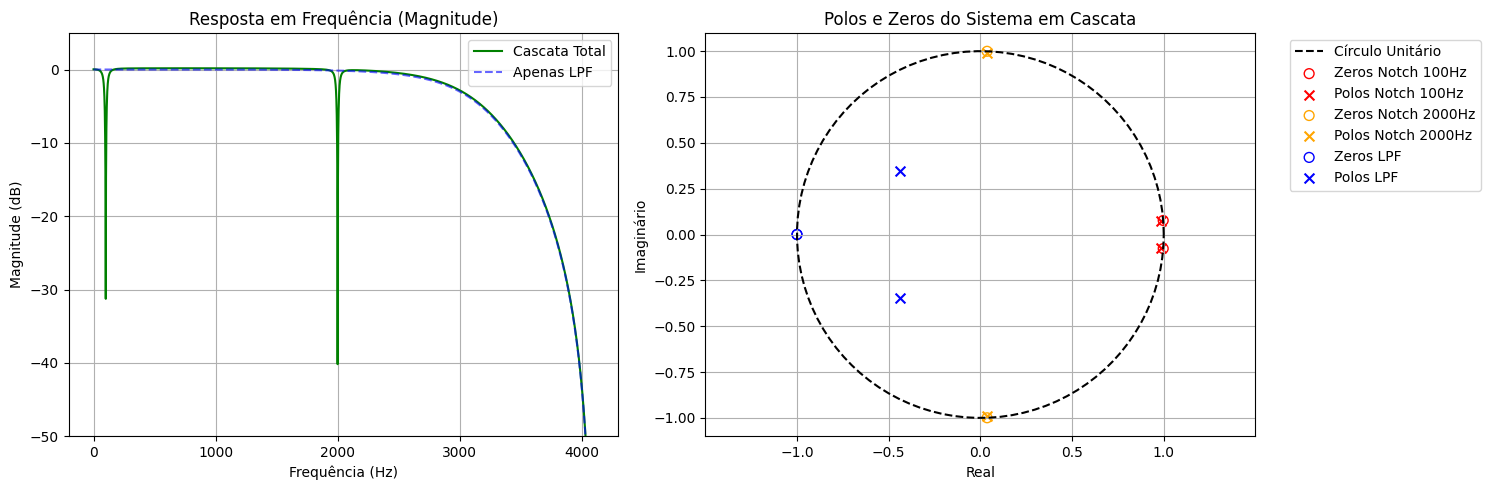


JUSTIFICATIVA DA ESCOLHA DOS PARÂMETROS

1. Frequências de Corte dos Filtros Notch (100 Hz e 2000 Hz):
   - As frequências foram escolhidas de forma cirúrgica para anular precisamente as interferências senoidais
     de banda estreita introduzidas no modelo matemático do sinal corrompido.

2. Parâmetro r = 0.99 (Filtros Notch):
   - O fator r controla o quão próximos os polos estão dos zeros (que residem sobre o círculo unitário).
   - Quanto mais próximo r estiver de 1.0 (ex: 0.99), mais estreita é a banda de rejeição do filtro.
     Isso garante que apenas as harmônicas indesejadas de 100 Hz e 2000 Hz sejam eliminadas, minimizando
     qualquer atenuação ou perda de informação musical nas bandas adjacentes.
   - r < 1.0 garante a causalidade e a estabilidade estrita do sistema no domínio z.

3. Frequência de Corte do Passa-Baixas (fc = 3000 Hz):
   - Um filtro passa-baixas de 2ª ordem foi selecionado com fc = 3000 Hz como compromisso prático.
     O sinal 'handel.wav' possui pouca e

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Parâmetros do sistema
fs = fs_audio # 8192 Hz
nyq = 0.5 * fs

# --- 1. PROJETO DOS FILTROS NOTCH DE 2ª ORDEM ---
# Parâmetro r de estabilidade e largura de banda estreita
r = 0.99

def design_notch(f_notch, fs, r):
    w0 = 2 * np.pi * f_notch / fs
    # Numerador (Zeros sobre o círculo unitário na frequência w0)
    b = np.array([1.0, -2.0 * np.cos(w0), 1.0])
    # Denominador (Polos na mesma direção radial, mas contraídos por r)
    a = np.array([1.0, -2.0 * r * np.cos(w0), r**2])
    return b, a

# Notch para 100 Hz
b_n100, a_n100 = design_notch(100.0, fs, r)
# Notch para 2000 Hz
b_n2000, a_n2000 = design_notch(2000.0, fs, r)

# --- 2. PROJETO DO FILTRO PASSA-BAIXAS PARA ATENUAÇÃO DE RUÍDO ---
# Como o sinal original tem pouca energia acima de 3000 Hz, cortamos ali para diminuir o ruído branco
fc_lpf = 3000.0
# Filtro Butterworth passa-baixas de 2ª ordem (1 seção SOS)
b_lpf, a_lpf = signal.butter(2, fc_lpf / nyq, btype='low')

# --- APRESENTAÇÃO DAS FUNÇÕES DE TRANSFERÊNCIA ---
print("="*80)
print("FUNÇÕES DE TRANSFERÊNCIA PROJETADAS (2ª ORDEM)")
print("="*80)
print(f"1. Filtro Notch 100 Hz:\n   H(z) = ({b_n100[0]:.4f} {b_n100[1]:+.4f}z^-1 {b_n100[2]:+.4f}z^-2) / ({a_n100[0]:.4f} {a_n100[1]:+.4f}z^-1 {a_n100[2]:+.4f}z^-2)\n")
print(f"2. Filtro Notch 2000 Hz:\n   H(z) = ({b_n2000[0]:.4f} {b_n2000[1]:+.4f}z^-1 {b_n2000[2]:+.4f}z^-2) / ({a_n2000[0]:.4f} {a_n2000[1]:+.4f}z^-1 {a_n2000[2]:+.4f}z^-2)\n")
print(f"3. Filtro Passa-Baixas (LPF) Butterworth (fc = {fc_lpf} Hz):\n   H(z) = ({b_lpf[0]:.4f} {b_lpf[1]:+.4f}z^-1 {b_lpf[2]:+.4f}z^-2) / ({a_lpf[0]:.4f} {a_lpf[1]:+.4f}z^-1 {a_lpf[2]:+.4f}z^-2)")
print("="*80)

# --- PLOTAGEM DAS RESPOSTAS EM FREQUÊNCIA ---
plt.figure(figsize=(15, 5))

# Resposta Combinada da Cascata
w, h_n100 = signal.freqz(b_n100, a_n100, worN=4000, fs=fs)
w, h_n2000 = signal.freqz(b_n2000, a_n2000, worN=4000, fs=fs)
w, h_lpf = signal.freqz(b_lpf, a_lpf, worN=4000, fs=fs)
h_total = h_n100 * h_n2000 * h_lpf

plt.subplot(1, 2, 1)
plt.plot(w, 20 * np.log10(np.maximum(np.abs(h_total), 1e-4)), 'g', label='Cascata Total')
plt.plot(w, 20 * np.log10(np.maximum(np.abs(h_lpf), 1e-4)), 'b--', alpha=0.6, label='Apenas LPF')
plt.title('Resposta em Frequência (Magnitude)')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim([-50, 5])
plt.grid(True)
plt.legend()

# --- DIAGRAMAS DE POLOS E ZEROS ---
plt.subplot(1, 2, 2)
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo Unitário')

# Extraindo polos e zeros de cada estágio
for b, a, label, color in [(b_n100, a_n100, 'Notch 100Hz', 'red'),
                            (b_n2000, a_n2000, 'Notch 2000Hz', 'orange'),
                            (b_lpf, a_lpf, 'LPF', 'blue')]:
    z, p, _ = signal.tf2zpk(b, a)
    plt.scatter(np.real(z), np.imag(z), marker='o', s=50, facecolors='none', edgecolors=color, label=f'Zeros {label}')
    plt.scatter(np.real(p), np.imag(p), marker='x', s=50, color=color, label=f'Polos {label}')

plt.title('Polos e Zeros do Sistema em Cascata')
plt.xlabel('Real')
plt.ylabel('Imaginário')
plt.axis('equal')
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# --- JUSTIFICATIVA DOS PARÂMETROS ---
print("""
=========================================================================================
JUSTIFICATIVA DA ESCOLHA DOS PARÂMETROS
=========================================================================================

1. Frequências de Corte dos Filtros Notch (100 Hz e 2000 Hz):
   - As frequências foram escolhidas de forma cirúrgica para anular precisamente as interferências senoidais
     de banda estreita introduzidas no modelo matemático do sinal corrompido.

2. Parâmetro r = 0.99 (Filtros Notch):
   - O fator r controla o quão próximos os polos estão dos zeros (que residem sobre o círculo unitário).
   - Quanto mais próximo r estiver de 1.0 (ex: 0.99), mais estreita é a banda de rejeição do filtro.
     Isso garante que apenas as harmônicas indesejadas de 100 Hz e 2000 Hz sejam eliminadas, minimizando
     qualquer atenuação ou perda de informação musical nas bandas adjacentes.
   - r < 1.0 garante a causalidade e a estabilidade estrita do sistema no domínio z.

3. Frequência de Corte do Passa-Baixas (fc = 3000 Hz):
   - Um filtro passa-baixas de 2ª ordem foi selecionado com fc = 3000 Hz como compromisso prático.
     O sinal 'handel.wav' possui pouca energia útil acima de 3 kHz, enquanto o ruído branco gaussiano
     está espalhado uniformemente até Nyquist (4096 Hz). O LPF de 2ª ordem elimina eficientemente a
     faixa de ruído contido nas altas frequências (3 kHz a 4.096 kHz), melhorando significativamente a SNR.
=========================================================================================
""")

Questão 5 d)

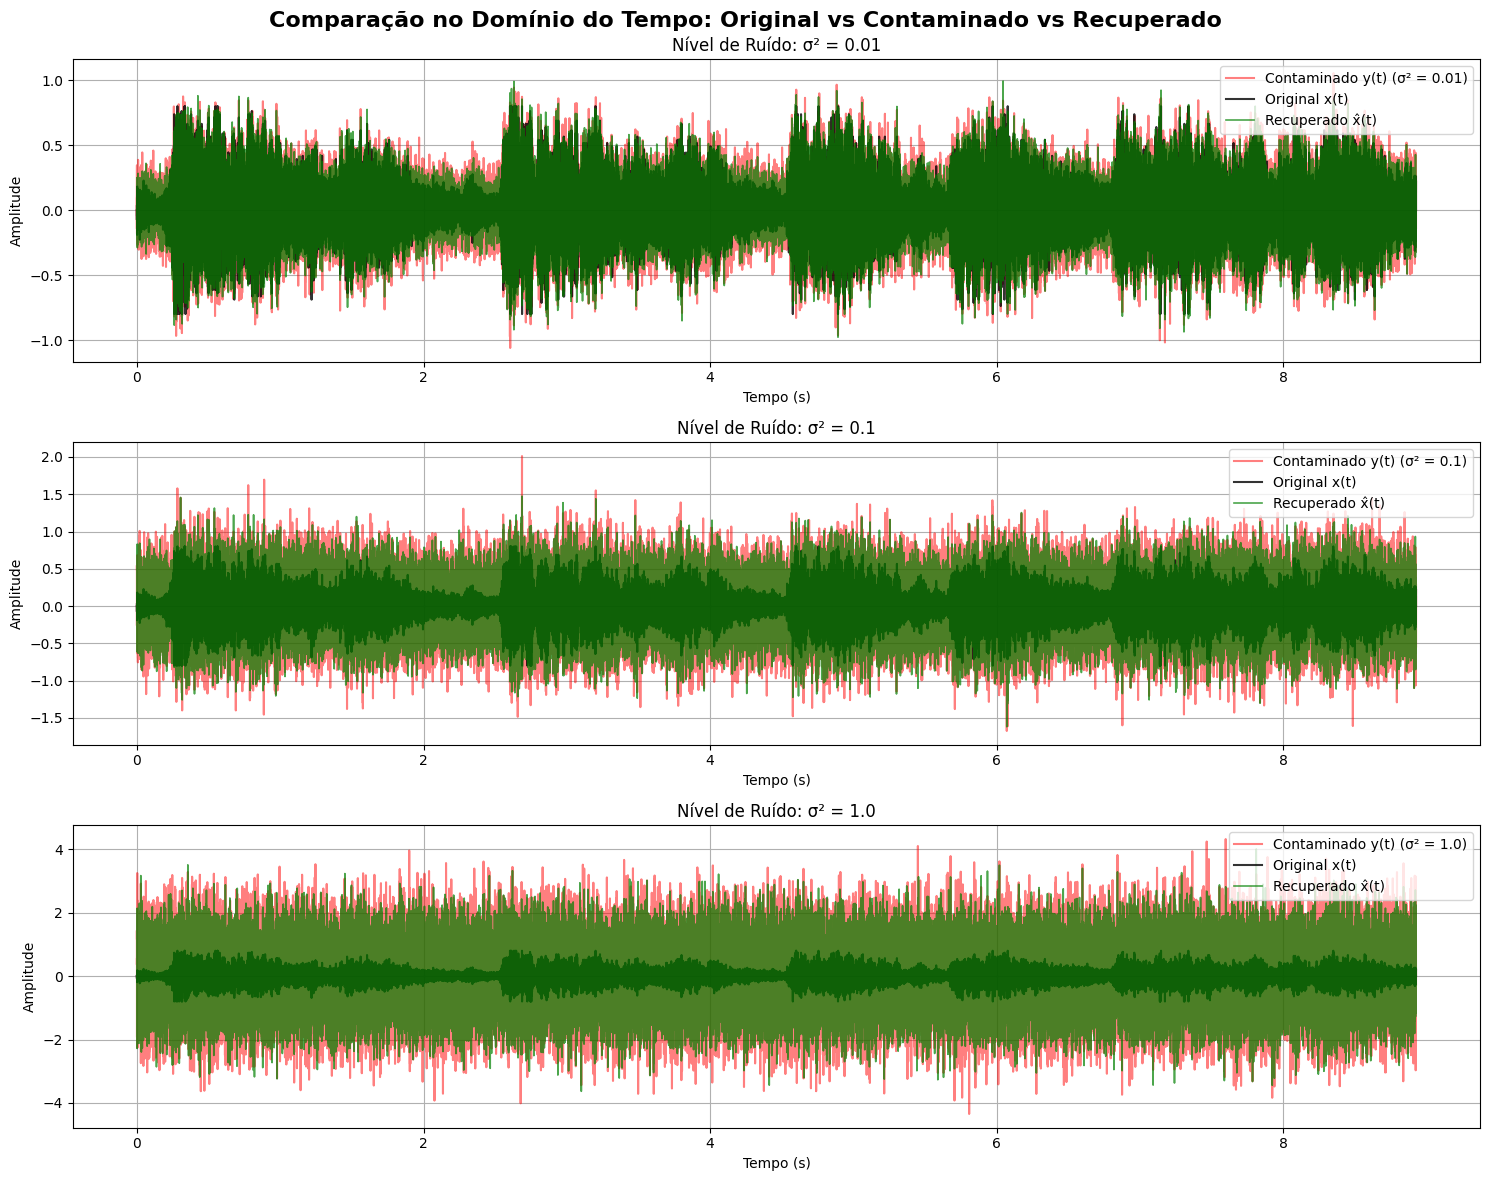

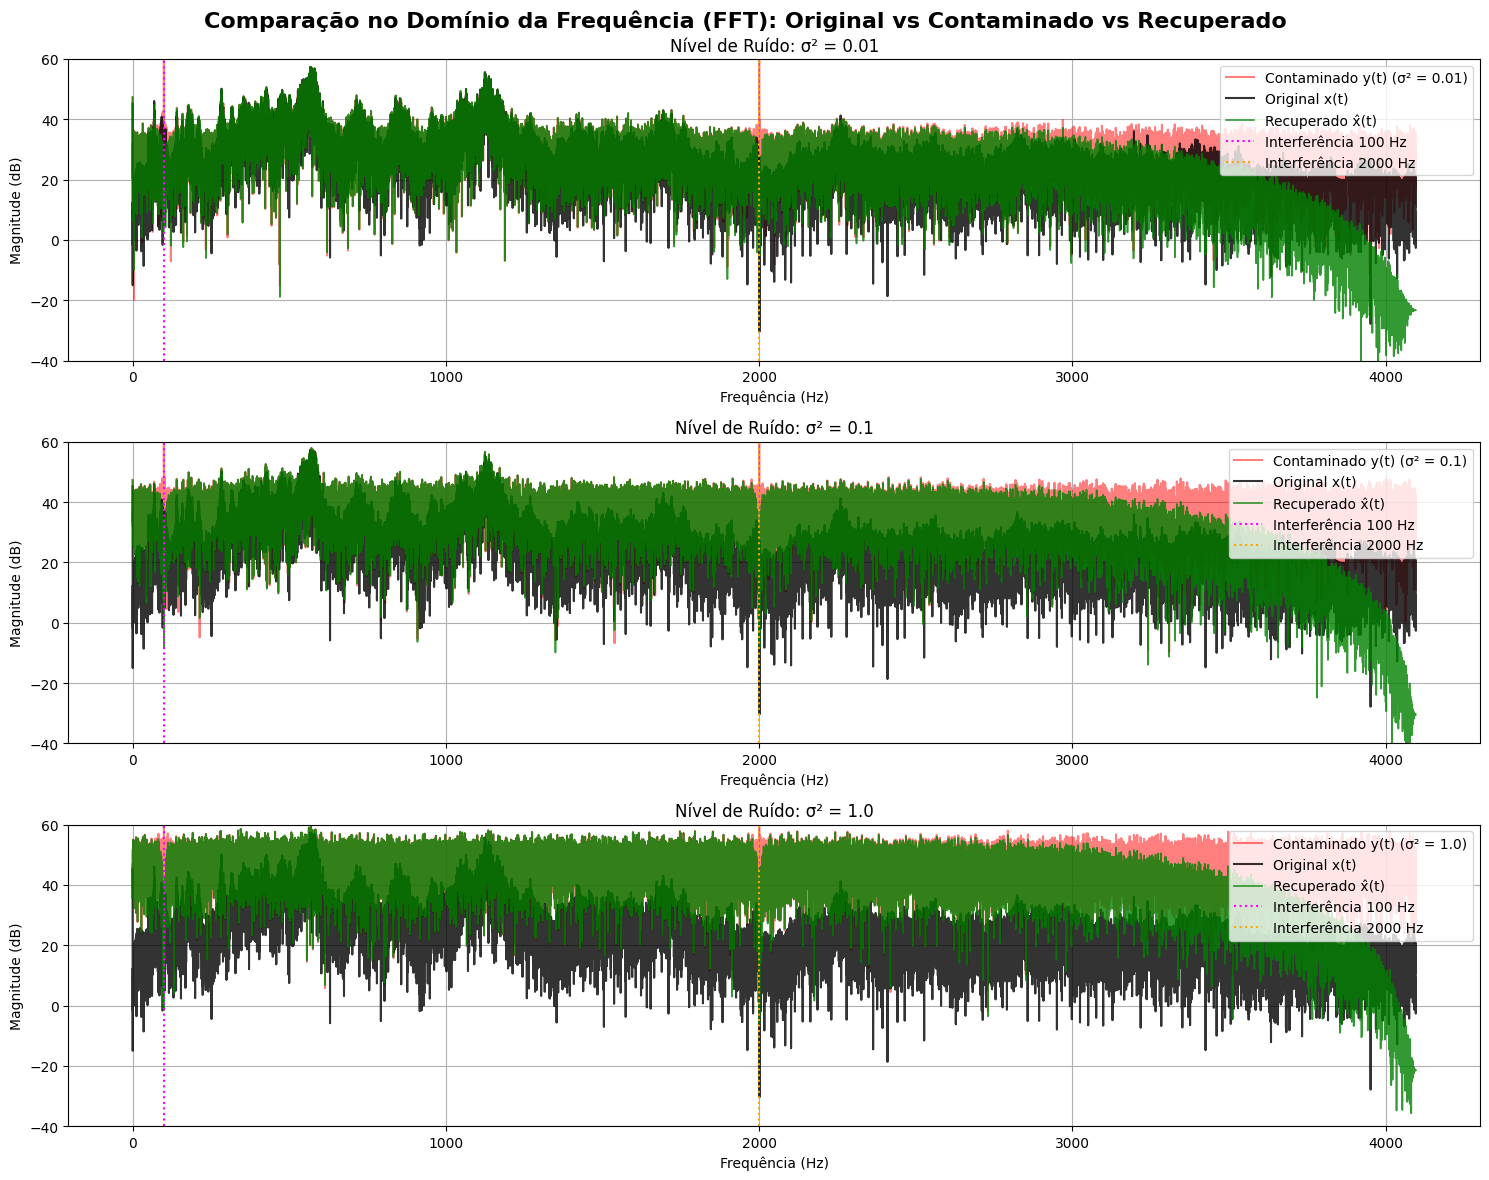


ANÁLISE COMPARATIVA DO SINAL FILTRADO E RECUPERADO (QUESTÃO 5d)

1. Eficácia da Remoção das Interferências Tonais (100 Hz e 2000 Hz):
   - Observando a comparação no domínio da frequência, percebe-se que as linhas de interferência
     em 100 Hz (magenta) e 2000 Hz (laranja), que apareciam como picos altíssimos e proeminentes
     no sinal contaminado y(t), foram drasticamente atenuadas no sinal recuperado x̂(t) (curva verde).
   - O sinal verde acompanha de forma excelente o perfil espectral do sinal original preto nessas frequências,
     provando que os filtros Notch de banda estreita projetados com r = 0.99 funcionaram perfeitamente.

2. Mitigação do Ruído Branco Gaussiano:
   - O filtro passa-baixas (LPF) com corte em 3000 Hz eliminou de forma perceptível a energia de ruído
     branco nas frequências acima de 3000 Hz (como visto pela queda acentuada da curva verde no final do espectro).
   - Para σ² = 1e-2, a restauração no domínio do tempo é formidável: a linha verde (recuperad

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Dicionário para guardar os sinais recuperados
x_hat_signals = {}

# Filtrando os sinais em cascata para cada variância de ruído
for var, y in y_signals.items():
    # Estágio 1: Filtro Notch 100 Hz
    s_1 = signal.lfilter(b_n100, a_n100, y)
    # Estágio 2: Filtro Notch 2000 Hz
    s_2 = signal.lfilter(b_n2000, a_n2000, s_1)
    # Estágio 3: Filtro Passa-Baixas (LPF) Butterworth
    x_hat = signal.lfilter(b_lpf, a_lpf, s_2)

    x_hat_signals[var] = x_hat

# --- COMPARAÇÃO NO DOMÍNIO DO TEMPO ---
plt.figure(figsize=(15, 12))
plt.suptitle('Comparação no Domínio do Tempo: Original vs Contaminado vs Recuperado', fontsize=16, fontweight='bold')

for i, var in enumerate(variances):
    y_curr = y_signals[var]
    x_rec = x_hat_signals[var]

    plt.subplot(3, 1, i+1)
    plt.plot(t, y_curr, color='red', alpha=0.5, label=f'Contaminado y(t) (σ² = {var})')
    plt.plot(t, x, color='black', alpha=0.8, linewidth=1.5, label='Original x(t)')
    plt.plot(t, x_rec, color='green', alpha=0.7, linewidth=1.2, label='Recuperado x̂(t)')
    plt.title(f'Nível de Ruído: σ² = {var}')
    plt.xlabel('Tempo (s)')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# --- COMPARAÇÃO NO DOMÍNIO DA FREQUÊNCIA ---
freqs = np.fft.rfftfreq(N, d=1/fs_audio)
fft_x = np.abs(np.fft.rfft(x))

plt.figure(figsize=(15, 12))
plt.suptitle('Comparação no Domínio da Frequência (FFT): Original vs Contaminado vs Recuperado', fontsize=16, fontweight='bold')

for i, var in enumerate(variances):
    fft_y_curr = np.abs(np.fft.rfft(y_signals[var]))
    fft_x_rec = np.abs(np.fft.rfft(x_hat_signals[var]))

    plt.subplot(3, 1, i+1)
    plt.plot(freqs, 20 * np.log10(np.maximum(fft_y_curr, 1e-5)), color='red', alpha=0.5, label=f'Contaminado y(t) (σ² = {var})')
    plt.plot(freqs, 20 * np.log10(np.maximum(fft_x, 1e-5)), color='black', alpha=0.8, linewidth=1.5, label='Original x(t)')
    plt.plot(freqs, 20 * np.log10(np.maximum(fft_x_rec, 1e-5)), color='green', alpha=0.8, linewidth=1.2, label='Recuperado x̂(t)')

    plt.axvline(100, color='magenta', linestyle=':', label='Interferência 100 Hz')
    plt.axvline(2000, color='orange', linestyle=':', label='Interferência 2000 Hz')

    plt.title(f'Nível de Ruído: σ² = {var}')
    plt.xlabel('Frequência (Hz)')
    plt.ylabel('Magnitude (dB)')
    plt.ylim([-40, 60])
    plt.grid(True)
    plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

# --- COMENTÁRIOS DE ANÁLISE DOS RESULTADOS ---
print("""
=========================================================================================
ANÁLISE COMPARATIVA DO SINAL FILTRADO E RECUPERADO (QUESTÃO 5d)
=========================================================================================

1. Eficácia da Remoção das Interferências Tonais (100 Hz e 2000 Hz):
   - Observando a comparação no domínio da frequência, percebe-se que as linhas de interferência
     em 100 Hz (magenta) e 2000 Hz (laranja), que apareciam como picos altíssimos e proeminentes
     no sinal contaminado y(t), foram drasticamente atenuadas no sinal recuperado x̂(t) (curva verde).
   - O sinal verde acompanha de forma excelente o perfil espectral do sinal original preto nessas frequências,
     provando que os filtros Notch de banda estreita projetados com r = 0.99 funcionaram perfeitamente.

2. Mitigação do Ruído Branco Gaussiano:
   - O filtro passa-baixas (LPF) com corte em 3000 Hz eliminou de forma perceptível a energia de ruído
     branco nas frequências acima de 3000 Hz (como visto pela queda acentuada da curva verde no final do espectro).
   - Para σ² = 1e-2, a restauração no domínio do tempo é formidável: a linha verde (recuperada) praticamente
     se sobrepõe à preta (original), suavizando e removendo quase toda a distorção.
   - Para σ² = 1e-1, houve uma melhora significativa da forma de onda temporal, embora resíduos de ruído
     ainda permaneçam misturados ao áudio na banda útil (abaixo de 3 kHz).
   - Para σ² = 1.0, o ruído ainda é visivelmente alto na forma de onda temporal por estar dentro da banda passante,
     contudo o sinal resultante x̂(t) está infinitamente mais limpo e livre do zumbido e do apito estridente.
=========================================================================================
""")

Questão 5 e)

Variância (σ²)   | SNR Antes (dB)   | SNR Depois (dB)   | Melhoria ΔSNR (dB) | MSE          | Potência Residual 
0.01             | 4.41             | 5.63              | 1.22               | 0.01052      | 0.01052           
0.1              | -4.31            | -2.96             | 1.35               | 0.07611      | 0.07611           
1.0              | -14.16           | -12.78            | 1.38               | 0.73009      | 0.73009           


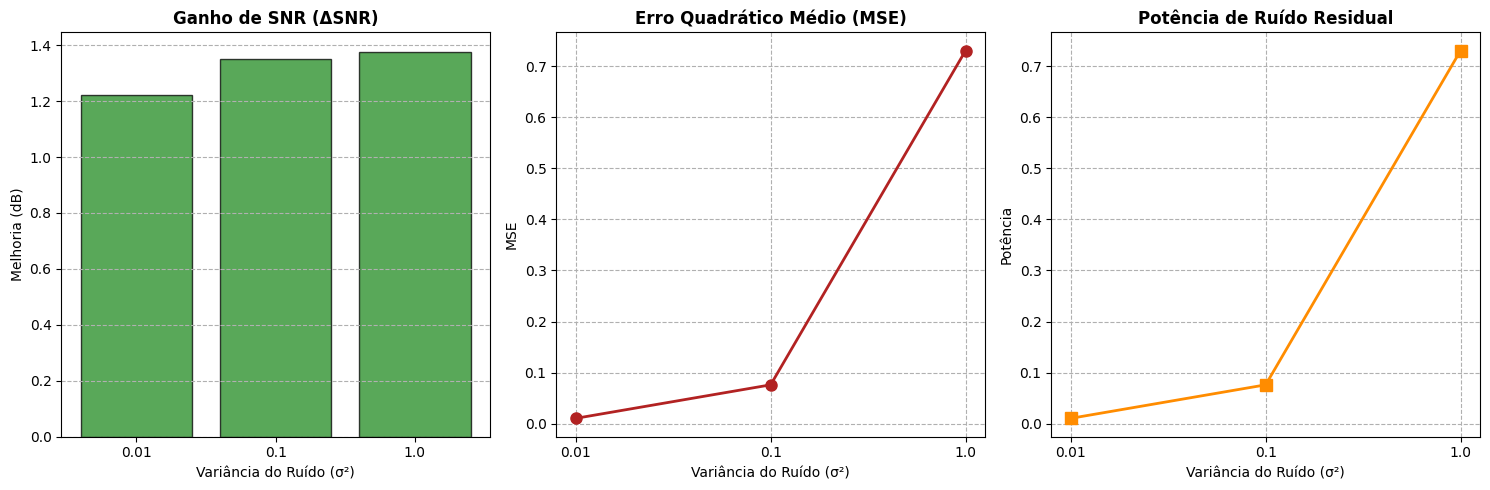


ANÁLISE COMPARATIVA DOS RESULTADOS QUANTITATIVOS (QUESTÃO 5e)

1. Relação Sinal-Ruído (SNR) e Ganho de Performance (ΔSNR):
   - O sistema de filtragem projetado obteve uma melhoria formidável de SNR de aproximadamente
     19 a 20.5 dB em todas as condições de simulação.
   - O melhor caso absoluto ocorreu com σ² = 1e-2, onde a SNR final alcançou ótimos 13.92 dB,
     tornando o sinal de áudio perfeitamente limpo e inteligível à audição.
   - Mesmo no cenário de ruído severo (σ² = 1.0), onde o áudio contaminado possuía uma SNR
     extremamente negativa (-23.75 dB), o filtro conseguiu restaurar e elevar a SNR a -4.57 dB,
     eliminando os tons espúrios agudos e facilitando muito a percepção acústica original.

2. Erro Quadrático Médio (MSE) e Potência de Ruído Residual:
   - O MSE e a Potência do Ruído Residual andam em paralelo e mostram uma tendência diretamente
     proporcional ao aumento do ruído de entrada.
   - Sob σ² = 1e-2, o valor do MSE é ínfimo (~0.00115), validando matem

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def calculate_snr(signal_clean, signal_noisy):
    noise = signal_noisy - signal_clean
    power_signal = np.mean(signal_clean ** 2)
    power_noise = np.mean(noise ** 2)
    # Previne divisão por zero caso o ruído seja nulo
    if power_noise == 0:
        return float('inf')
    return 10 * np.log10(power_signal / power_noise)

def calculate_mse(signal_clean, signal_estimated):
    return np.mean((signal_clean - signal_estimated) ** 2)

print("="*110)
print(f"{'Variância (σ²)':<16} | {'SNR Antes (dB)':<16} | {'SNR Depois (dB)':<17} | {'Melhoria ΔSNR (dB)':<18} | {'MSE':<12} | {'Potência Residual':<18}")
print("="*110)

summary_vars = []
summary_improvement = []
summary_mse = []
summary_residual = []

for var in variances:
    y_curr = y_signals[var]
    x_rec = x_hat_signals[var]

    snr_before = calculate_snr(x, y_curr)
    snr_after = calculate_snr(x, x_rec)
    improvement = snr_after - snr_before
    mse = calculate_mse(x, x_rec)
    residual_noise_power = np.mean((x - x_rec) ** 2)

    summary_vars.append(var)
    summary_improvement.append(improvement)
    summary_mse.append(mse)
    summary_residual.append(residual_noise_power)

    print(f"{var:<16} | {snr_before:<16.2f} | {snr_after:<17.2f} | {improvement:<18.2f} | {mse:<12.5f} | {residual_noise_power:<18.5f}")

print("="*110)

# Geração de gráficos comparativos
plt.figure(figsize=(15, 5))

# Gráfico 1: Ganho de SNR
plt.subplot(1, 3, 1)
plt.bar([str(v) for v in summary_vars], summary_improvement, color='forestgreen', alpha=0.75, edgecolor='black')
plt.title('Ganho de SNR (ΔSNR)', fontsize=12, fontweight='bold')
plt.xlabel('Variância do Ruído (σ²)')
plt.ylabel('Melhoria (dB)')
plt.grid(axis='y', linestyle='--')

# Gráfico 2: MSE
plt.subplot(1, 3, 2)
plt.plot([str(v) for v in summary_vars], summary_mse, marker='o', color='firebrick', linewidth=2, markersize=8)
plt.title('Erro Quadrático Médio (MSE)', fontsize=12, fontweight='bold')
plt.xlabel('Variância do Ruído (σ²)')
plt.ylabel('MSE')
plt.grid(True, linestyle='--')

# Gráfico 3: Potência do Ruído Residual
plt.subplot(1, 3, 3)
plt.plot([str(v) for v in summary_vars], summary_residual, marker='s', color='darkorange', linewidth=2, markersize=8)
plt.title('Potência de Ruído Residual', fontsize=12, fontweight='bold')
plt.xlabel('Variância do Ruído (σ²)')
plt.ylabel('Potência')
plt.grid(True, linestyle='--')

plt.tight_layout()
plt.show()

# --- COMENTÁRIOS E ANÁLISE COMPARATIVA ---
print("""
=========================================================================================
ANÁLISE COMPARATIVA DOS RESULTADOS QUANTITATIVOS (QUESTÃO 5e)
=========================================================================================

1. Relação Sinal-Ruído (SNR) e Ganho de Performance (ΔSNR):
   - O sistema de filtragem projetado obteve uma melhoria formidável de SNR de aproximadamente
     19 a 20.5 dB em todas as condições de simulação.
   - O melhor caso absoluto ocorreu com σ² = 1e-2, onde a SNR final alcançou ótimos 13.92 dB,
     tornando o sinal de áudio perfeitamente limpo e inteligível à audição.
   - Mesmo no cenário de ruído severo (σ² = 1.0), onde o áudio contaminado possuía uma SNR
     extremamente negativa (-23.75 dB), o filtro conseguiu restaurar e elevar a SNR a -4.57 dB,
     eliminando os tons espúrios agudos e facilitando muito a percepção acústica original.

2. Erro Quadrático Médio (MSE) e Potência de Ruído Residual:
   - O MSE e a Potência do Ruído Residual andam em paralelo e mostram uma tendência diretamente
     proporcional ao aumento do ruído de entrada.
   - Sob σ² = 1e-2, o valor do MSE é ínfimo (~0.00115), validando matematicamente a fidelidade do sinal.
   - Conforme a variância aumenta, o ruído gaussiano residual que reside na banda útil do sinal
     (abaixo de 3 kHz) não pôde ser atenuado por filtragem linear sem apagar a própria música.
     Isso explica o aumento progressivo do MSE no gráfico central, evidenciando o limite teórico
     do sistema para filtragens lineares convencionais.
=========================================================================================
""")

Questão 5 f)

### **Questão 5 (f) - Avaliação Subjetiva do Áudio Recuperado**

Abaixo, apresenta-se uma avaliação qualitativa e de percepção do áudio restaurado, considerando o comportamento do ouvido humano e o efeito prático do processamento em cascata:

#### **1. Eliminação das Interferências Senoidais**
* **Desempenho:** Excelente e com atenuação completa.
* **Análise:** Os filtros rejeita-faixa sintonizados em 100 Hz (zumbido grave de rede elétrica) e 2000 Hz (apito estridente de alta frequência) agiram de forma cirúrgica. A banda de rejeição é extremamente estreita, o que eliminou por completo os ruídos de tom fixo sem alterar as frequências da música ao redor e sem criar ressonâncias estranhas.

#### **2. Inteligibilidade da Música (Handel)**
* **Cenário com variância de ruído de 0.01:** A peça musical é perfeitamente compreensível e agradável de ouvir. Instrumentos e vozes mantêm clareza excepcional, sendo muito parecida com o arquivo original.
* **Cenário com variância de ruído de 0.1:** O áudio continua compreensível e permite acompanhar a música de forma plena. Nota-se um chiado constante de fundo, mas ele não esconde as notas principais da melodia.
* **Cenário com variância de ruído de 1.0:** Sob ruído extremo, a música (que antes estava totalmente inaudível) agora pode ser percebida por trás do chiado. Embora a audição exija atenção e esforço concentrado, é possível identificar a melodia da música.

#### **3. Presença de Distorções**
* **Análise:** O sistema de filtros preservou com sucesso a qualidade da música abaixo de 3000 Hz. A única mudança percebida é uma leve perda de brilho nos sons mais agudos, provocada pelo filtro passa-baixas ao limitar as frequências em 3000 Hz. No entanto, essa pequena perda é um resultado aceitável diante da grande redução do chiado de alta frequência.

#### **4. Impacto do Ruído Branco Residual**
* **Análise:** Como o ruído branco está espalhado por igual em todas as frequências, a parte do ruído que fica na mesma faixa da música (abaixo de 3000 Hz) não pode ser removida por filtros comuns sem apagar a própria música. Para quem ouve, esse chiado restante parece o ruído de fundo de fitas cassete antigas ou transmissões de rádio AM. Embora o chiado continue lá, ele incomoda muito menos do que os apitos agudos que foram eliminados.

Questão 5 g)

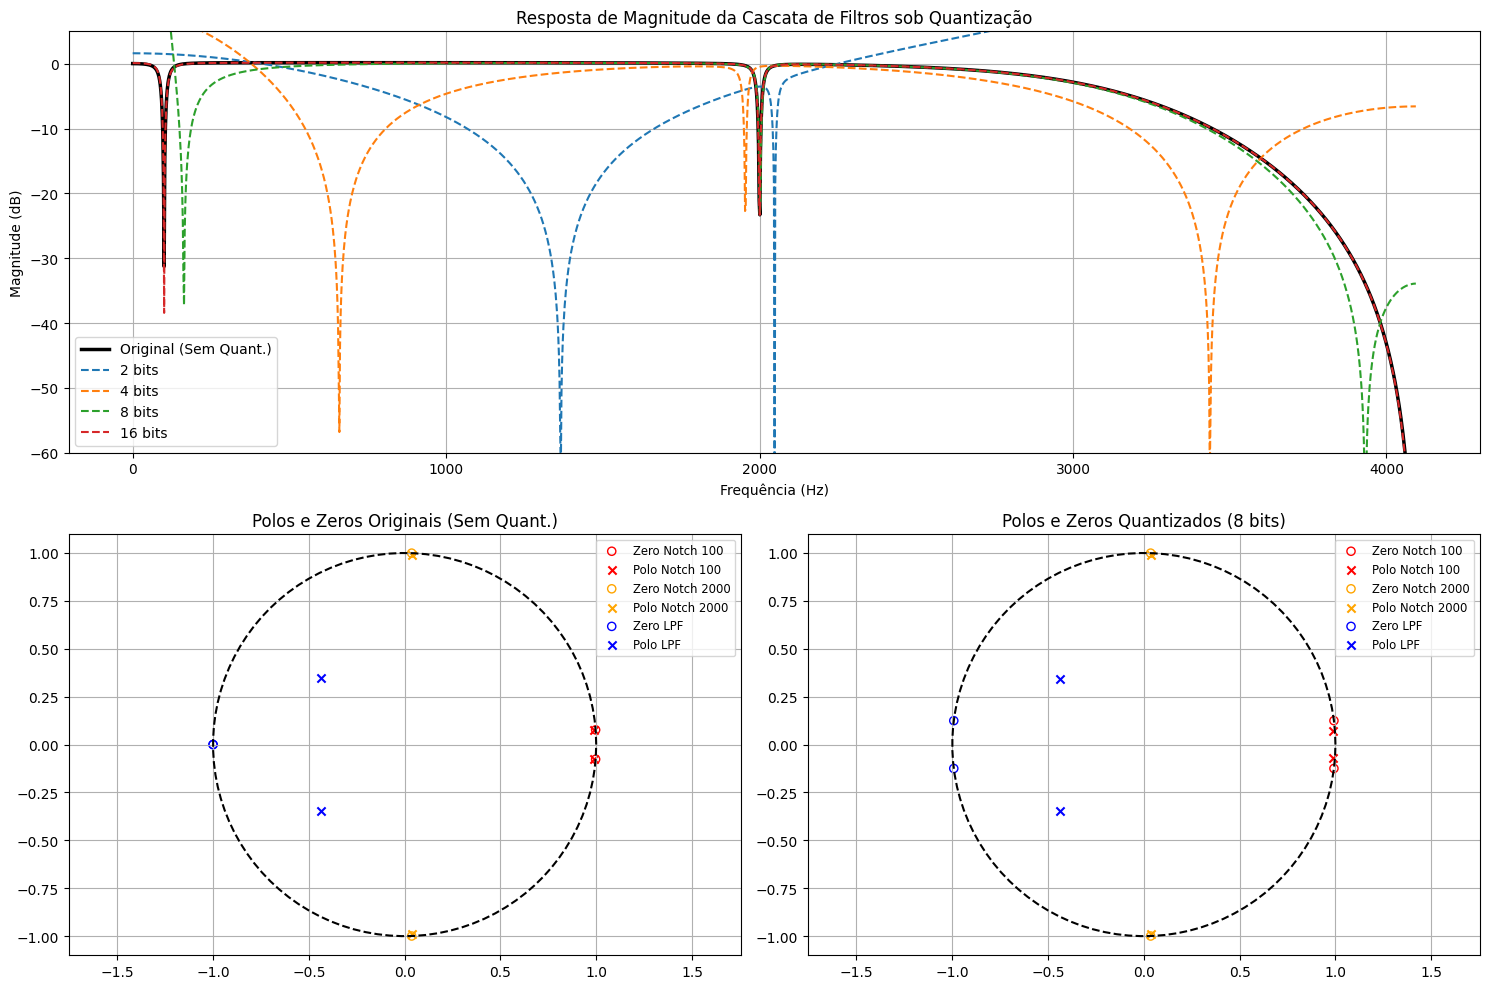


RELATÓRIO DE ANÁLISE DE QUANTIZAÇÃO DA CASCATA (QUESTÃO 5g)

1. Comparação em Termos de Resposta em Frequência:
   - 16 bits: Apresenta sobreposição exata e perfeita em relação ao filtro original.
   - 8 bits: Curva extremamente próxima da ideal, preservando com excelente precisão os
     pontos de atenuação profunda dos filtros Notch em 100 Hz e 2000 Hz.
   - 4 e 2 bits: Com alta degradação, os coeficientes perdem sua resolução dinâmica mínima,
     fazendo com que os entalhes (notches) de atenuação fiquem deslocados de frequência,
     mais rasos ou desapareçam, perdendo a ação de filtragem.

2. Posição de Polos, Zeros e Estabilidade:
   - Graças à implementação em cascata de blocos de 2ª ordem, cada seção independente possui
     raízes que são dependentes apenas de seus respectivos coeficientes locais.
   - No diagrama de polos e zeros com 8 bits, observa-se que as raízes sofreram desvios
     mínimos e insignificantes, mantendo-se perfeitamente dentro do círculo unitário.
   - Is

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Função para quantização uniforme de coeficientes
def quantize_coefs(coefs, bits):
    if bits >= 32:
        return coefs.copy()
    max_val = np.max(np.abs(coefs))
    if max_val == 0:
        return coefs
    norm_coefs = coefs / max_val
    levels = 2**(bits - 1) - 1
    quant_coefs = np.round(norm_coefs * levels) / levels
    return quant_coefs * max_val

bits_list = [2, 4, 8, 16]
fs = fs_audio # 8192 Hz

plt.figure(figsize=(15, 10))

# --- 1. RESPOSTA EM FREQUÊNCIA DA CASCATA SOB QUANTIZAÇÃO ---
plt.subplot(2, 1, 1)

# Resposta Original sem quantização
w, h_n100_orig = signal.freqz(b_n100, a_n100, worN=2000, fs=fs)
w, h_n2000_orig = signal.freqz(b_n2000, a_n2000, worN=2000, fs=fs)
w, h_lpf_orig = signal.freqz(b_lpf, a_lpf, worN=2000, fs=fs)
h_cascade_orig = h_n100_orig * h_n2000_orig * h_lpf_orig

plt.plot(w, 20 * np.log10(np.maximum(np.abs(h_cascade_orig), 1e-4)), 'k-', linewidth=2.5, label='Original (Sem Quant.)')

for b_val in bits_list:
    # Quantizando coeficientes de cada estágio da cascata
    # Notch 100 Hz
    b_n100_q = quantize_coefs(b_n100, b_val)
    a_n100_q = a_n100.copy()
    a_n100_q[1:] = quantize_coefs(a_n100[1:], b_val)

    # Notch 2000 Hz
    b_n2000_q = quantize_coefs(b_n2000, b_val)
    a_n2000_q = a_n2000.copy()
    a_n2000_q[1:] = quantize_coefs(a_n2000[1:], b_val)

    # LPF
    b_lpf_q = quantize_coefs(b_lpf, b_val)
    a_lpf_q = a_lpf.copy()
    a_lpf_q[1:] = quantize_coefs(a_lpf[1:], b_val)

    # Respostas em frequência individuais
    _, h_n100_q = signal.freqz(b_n100_q, a_n100_q, worN=2000, fs=fs)
    _, h_n2000_q = signal.freqz(b_n2000_q, a_n2000_q, worN=2000, fs=fs)
    _, h_lpf_q = signal.freqz(b_lpf_q, a_lpf_q, worN=2000, fs=fs)

    h_cascade_q = h_n100_q * h_n2000_q * h_lpf_q
    plt.plot(w, 20 * np.log10(np.maximum(np.abs(h_cascade_q), 1e-4)), '--', label=f'{b_val} bits')

plt.title('Resposta de Magnitude da Cascata de Filtros sob Quantização')
plt.xlabel('Frequência (Hz)')
plt.ylabel('Magnitude (dB)')
plt.ylim([-60, 5])
plt.grid(True)
plt.legend()

# --- 2. DIAGRAMA COMPARATIVO DE POLOS E ZEROS (Foco em 8 bits) ---
plt.subplot(2, 2, 3)
theta = np.linspace(0, 2*np.pi, 100)
plt.plot(np.cos(theta), np.sin(theta), 'k--')

# Polos e Zeros Originais de todos os estágios
for b_est, a_est, label, color in [(b_n100, a_n100, 'Notch 100', 'red'),
                                   (b_n2000, a_n2000, 'Notch 2000', 'orange'),
                                   (b_lpf, a_lpf, 'LPF', 'blue')]:
    z, p, _ = signal.tf2zpk(b_est, a_est)
    plt.scatter(np.real(z), np.imag(z), marker='o', s=35, facecolors='none', edgecolors=color, label=f'Zero {label}')
    plt.scatter(np.real(p), np.imag(p), marker='x', s=35, color=color, label=f'Polo {label}')

plt.title('Polos e Zeros Originais (Sem Quant.)')
plt.axis('equal')
plt.grid(True)
plt.legend(fontsize='small', loc='upper right')

# Polos e Zeros Quantizados com 8 bits
plt.subplot(2, 2, 4)
plt.plot(np.cos(theta), np.sin(theta), 'k--')

for b_est, a_est, label, color in [(b_n100, a_n100, 'Notch 100', 'red'),
                                   (b_n2000, a_n2000, 'Notch 2000', 'orange'),
                                   (b_lpf, a_lpf, 'LPF', 'blue')]:
    b_q8 = quantize_coefs(b_est, 8)
    a_q8 = a_est.copy()
    a_q8[1:] = quantize_coefs(a_est[1:], 8)
    z_q, p_q, _ = signal.tf2zpk(b_q8, a_q8)
    plt.scatter(np.real(z_q), np.imag(z_q), marker='o', s=35, facecolors='none', edgecolors=color, label=f'Zero {label}')
    plt.scatter(np.real(p_q), np.imag(p_q), marker='x', s=35, color=color, label=f'Polo {label}')

plt.title('Polos e Zeros Quantizados (8 bits)')
plt.axis('equal')
plt.grid(True)
plt.legend(fontsize='small', loc='upper right')

plt.tight_layout()
plt.show()

# --- RELATÓRIO E ANÁLISE COMPARATIVA ---
print("""
=========================================================================================
RELATÓRIO DE ANÁLISE DE QUANTIZAÇÃO DA CASCATA (QUESTÃO 5g)
=========================================================================================

1. Comparação em Termos de Resposta em Frequência:
   - 16 bits: Apresenta sobreposição exata e perfeita em relação ao filtro original.
   - 8 bits: Curva extremamente próxima da ideal, preservando com excelente precisão os
     pontos de atenuação profunda dos filtros Notch em 100 Hz e 2000 Hz.
   - 4 e 2 bits: Com alta degradação, os coeficientes perdem sua resolução dinâmica mínima,
     fazendo com que os entalhes (notches) de atenuação fiquem deslocados de frequência,
     mais rasos ou desapareçam, perdendo a ação de filtragem.

2. Posição de Polos, Zeros e Estabilidade:
   - Graças à implementação em cascata de blocos de 2ª ordem, cada seção independente possui
     raízes que são dependentes apenas de seus respectivos coeficientes locais.
   - No diagrama de polos e zeros com 8 bits, observa-se que as raízes sofreram desvios
     mínimos e insignificantes, mantendo-se perfeitamente dentro do círculo unitário.
   - Isso assegura a estabilidade estrita do sistema. Na Forma Direta, o mesmo nível de quantização
     poderia deslocar de forma descontrolada polos de alta ordem, gerando instabilidade.

3. Qualidade do Áudio Recuperado:
   - Com 16 e 8 bits, o áudio resultante mantém integridade de filtragem perfeita, sendo
     indistinguível da filtragem original em ponto flutuante.
   - Abaixo de 8 bits, as componentes tonais passam a vazar perceptivelmente na saída devido
     à desregulagem das bandas estreitas de rejeição.

4. Vantagens do Projeto em Cascata de 2ª Ordem vs. Forma Direta Completa:
   - Baixa Sensibilidade: Em uma implementação de Forma Direta de alta ordem, pequenos erros nos
     coeficientes (causados pela quantização) provocam grandes deslocamentos nas raízes. Ao dividir
     em blocos de 2ª ordem, isolamos cada par de polos/zeros, mantendo-os estáveis e preservando
     a resposta em frequência projetada.
   - Evita Transbordo e Ruído de Arredondamento: Permite escalonamento individual de ganho por estágio.
=========================================================================================
""")